# TP: Estimación de movimiento y seguimiento de objetos

**Cátedra:** Visión por Computadora — 5to Año
**FICH-UNL (Santa Fe, Argentina)**

El objetivo es comprender los pasos del pipeline completo:

`Imagen → Preprocesamiento → Modelado de fondo / detección → Seguimiento → Análisis`

No se muestran *todas* las técnicas, sino un subconjunto representativo, y cada bloque termina en una **aplicación real**:

| Bloque | Técnicas usadas | Aplicación real |
|---|---|---|
| 1. Preprocesamiento | Filtros espaciales, ROI, submuestreo | Robustez frente a ruido de sensor |
| 2. Modelado de fondo | Diferencia de cuadros, promedio móvil, **MOG2**, **KNN**, **CNT** | Comparación de costo/calidad |
| 3. Objeto abandonado | Dos MOG2 con distinta tasa de aprendizaje | Alarma de seguridad (equipaje olvidado) |
| 4. Multi-objeto | MOG2 + **Kalman** + asignación húngara | Conteo bidireccional, mapa de calor, tiempo de permanencia, velocidad |
| 5. Flujo óptico | **Farnebäck**, **DIS**, **Lucas-Kanade + GFTT** | Estabilización de video y detección de contraflujo |
| 6. Seguimiento de un objeto | **KCF, MOSSE, CSRT, TLD** | Prueba de oclusión (corta y larga) y cámara PTZ digital (auto-encuadre) |

**Cómo se usa:** ejecutar las celdas en orden. Al final de cada sección hay **consignas y reflexiones** para el informe del TP.

> Los tiempos (FPS) dependen de tu máquina; lo importante es la comparación *relativa* entre métodos.

## Celda de Configuración Inicial
Ejecutá esta celda para instalar/cargar las dependencias esenciales para este práctico.

In [ ]:
# Si hace falta, descomentar. Se usa la versión "headless" (no abre ventanas, ideal para notebooks).
# El paquete "contrib" incluye cv2.bgsegm (CNT, GSOC, ...) y los trackers legacy (MOSSE, TLD, ...)
%pip install -q opencv-contrib-python-headless numpy scipy matplotlib

In [9]:
import cv2, time, shutil, subprocess, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from IPython.display import Video, display


In [10]:

plt.rcParams['figure.dpi'] = 110
print('OpenCV', cv2.__version__)
assert hasattr(cv2, 'bgsegm') and hasattr(cv2, 'legacy'), \
    'Instalar opencv-contrib-python-headless (y desinstalar opencv-python si estaba instalado)'

DATOS = Path('datos');   DATOS.mkdir(exist_ok=True)
SALIDAS = Path('salidas'); SALIDAS.mkdir(exist_ok=True)

# Video de muestra: peatones (escena PETS, cámara fija). Se descarga la primera vez.
# Para usar TU video: poner su ruta en VIDEO_PROPIO (ej. 'datos/mi_video.mp4').
VIDEO_PROPIO = None
URL_PEATONES = 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/vtest.avi'

def obtener_video():
    if VIDEO_PROPIO: return VIDEO_PROPIO
    ruta = DATOS / 'vtest.avi'
    if not ruta.exists():
        print('Descargando video de muestra...'); urllib.request.urlretrieve(URL_PEATONES, ruta)
    return str(ruta)

OpenCV 4.14.0


In [13]:
# ---------- utilidades generales  ----------
def leer_frames(ruta, max_frames=400, escala=0.6, inicio=0):
    cap = cv2.VideoCapture(ruta)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    cap.set(cv2.CAP_PROP_POS_FRAMES, inicio)
    frames = []
    while len(frames) < max_frames:
        ok, f = cap.read()
        if not ok: break
        if escala != 1: f = cv2.resize(f, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
        frames.append(f)
    cap.release()
    return frames, fps

def gris(f): 
    return cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)

def mostrar(imgs, titulos=None, cols=3, ancho=5, cmap='gray'):
    n = len(imgs); filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(ancho * cols, ancho * 0.72 * filas))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs: ax.axis('off')
    for i, im in enumerate(imgs):
        if im.ndim == 3: axs[i].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:            axs[i].imshow(im, cmap=cmap, vmin=0, vmax=255)
        if titulos: axs[i].set_title(titulos[i], fontsize=10)
    plt.tight_layout(); plt.show()

def iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx)); iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / (aw * ah + bw * bh - inter + 1e-9)

def nuevo_writer(nombre, fps, tam):
    ruta = SALIDAS / nombre
    return cv2.VideoWriter(str(ruta), cv2.VideoWriter_fourcc(*'mp4v'), fps, tam), ruta

def ver_video(ruta, ancho=560):
    # mp4v no siempre se reproduce en el navegador: si hay ffmpeg se recodifica a H.264
    ruta = Path(ruta)
    if shutil.which('ffmpeg'):
        h264 = ruta.with_name(ruta.stem + '_h264.mp4')
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(ruta), '-vcodec', 'libx264',
                        '-pix_fmt', 'yuv420p', str(h264)])
        if h264.exists():
            display(Video(str(h264), embed=True, width=ancho)); return
    print(f'Video guardado en {ruta} (abrirlo con un reproductor externo).')



400 frames de 461x346 a 10 fps


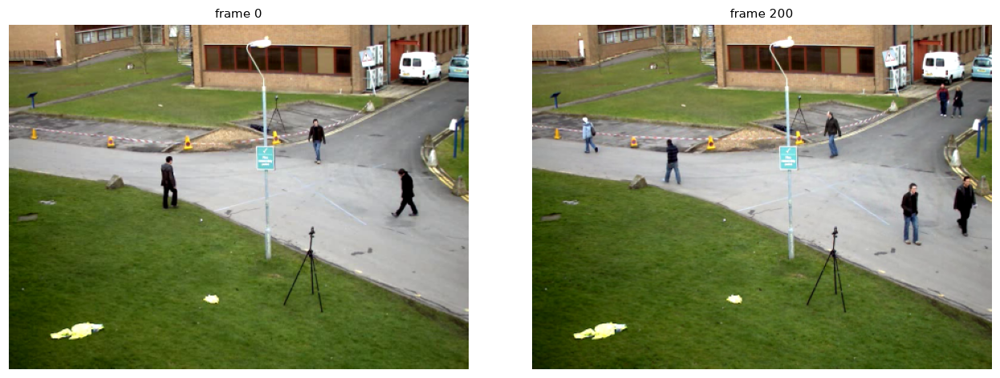

In [14]:
ESCALA = 0.6                       # los cuadros de trabajo se reducen para acelerar el procesamiento
frames, FPS = leer_frames(obtener_video(), max_frames=400, escala=ESCALA)
H, W = frames[0].shape[:2]
print(f'{len(frames)} frames de {W}x{H} a {FPS:.0f} fps')
mostrar([frames[0], frames[200]], ['frame 0', 'frame 200'], cols=2, ancho=6)

## 1. La importancia del preprocesamiento: señal vs. ruido

En la teoría se explicó que *si el ruido no se filtra, el modelo estadístico detectará movimiento falso*.

En este ejercicio vamos a simular un sensor malo (por ejemplo una cámara defectuosa) agregando ruido sal y pimienta (1 %) **distinto en cada cuadro** y vemos qué le pasa a un sustractor de fondo (MOG2).

> Aquí queremos ver que sucede con y sin filtrado de ruido.

In [17]:
import os

os.startfile(obtener_video())

In [12]:
display(Video(obtener_video(), embed=True))

In [3]:
rng = np.random.default_rng(0)

# Agrega ruido impulsivo de tipo "sal y pimienta".
# p representa la proporción aproximada de píxeles afectados.
# La mitad de los píxeles afectados se llevan a negro (pimienta) y la otra mitad a blanco (sal).
def ruido_sal_pimienta(f, p=0.01):
    r = rng.random(f.shape[:2])
    g = f.copy()
    g[r < p / 2] = 0              # Ruido "pimienta": píxeles negros.
    g[r > 1 - p / 2] = 255        # Ruido "sal": píxeles blancos.
    return g

def pipeline_fondo(frames, prefiltro=None, n=120):
    # Crear MOG2 con los mismos parámetros en todas las variantes.
    # detectShadows=False evita que las sombras se incorporen a la máscara como una categoría adicional.
    mog = cv2.createBackgroundSubtractorMOG2(
        history=200,
        varThreshold=25,
        detectShadows=False
    )
    # Procesar los primeros n frames.
    for f in frames[:n]:
        # Agregar ruido antes de aplicar el eventual filtro.
        g = ruido_sal_pimienta(f)
        # Aplicar el prefiltro seleccionado, si corresponde.
        if prefiltro:
            g = prefiltro(g)
        # Actualizar el modelo de fondo y obtener la máscara.
        m = mog.apply(g)
    return m

# Variantes utilizadas para comparar el efecto del ruido y filtros sobre la segmentación del fondo.
# - None en "Sin ruido": se procesa el frame original.
# - None en "Con ruido": se agrega ruido pero no se aplica filtro.
# - Mediana: especialmente útil para eliminar ruido impulsivo.
# - Gaussiano: realiza un suavizado más general de la imagen.
variantes = {
    'Sin ruido (frame original)': None,
    'Con ruido, sin filtrar': None,
    'Con ruido, filtrado con mediana 5x5': lambda f: cv2.medianBlur(f, 5),
    'Con ruido, filtrado con gaussiano 5x5': lambda f: cv2.GaussianBlur(f, (5, 5), 0),
}

# Procesar cada variante y guardar la máscara final obtenida.
mascaras, titulos = [], []
for nombre, pf in variantes.items():
    # Se utiliza directamente el frame original,  sin agregar ruido ni aplicar ningún prefiltro.
    if nombre.startswith('Sin ruido'):
        mog = cv2.createBackgroundSubtractorMOG2(
            history=200,
            varThreshold=25,
            detectShadows=False
        )
        for f in frames[:120]:
            m = mog.apply(f)
    else:
        # El pipeline agrega primero el ruido y luego aplica el filtro indicado.
        m = pipeline_fondo(frames, pf)

    mascaras.append(m)

    # Calcular qué porcentaje de píxeles de la máscara fueron clasificados como primer plano (valor > 0).
    titulos.append(
        f'{nombre}\n'
        f'{100 * (m > 0).mean():.2f}% píxeles en primer plano'
    )

# Mostrar las máscaras finales de las cuatro variantes.
mostrar(mascaras, titulos, cols=4, ancho=4.5)

KeyboardInterrupt: 

### **Reducción de carga computacional.**
Además del filtrado, podemos incluir otros procesos como parte del preprocesamiento:
* extracción de una ROI (**Region-Of-Interest**) y procesamos una región más acotada.
* reducir la resolución (**submuestreo espacial**) en los casos que sean adecuados.
* saltear cuadros (**diezmado temporal**), dependerá del caso particular. No será lo mismo evaluar un auto de F1 que el avance de una tortuga 😅.

A continuación **Medimos** el tiempo usando algunas de estas variantes con MOG2:

In [ ]:
def tiempo_mog2(lista, n=100):
    # Crear el sustractor MOG2 con los mismos parámetros para todos los casos evaluados.
    mog = cv2.createBackgroundSubtractorMOG2(
        history=200,
        varThreshold=25,
        detectShadows=True
    )
    # Medir únicamente el tiempo empleado por MOG2 en procesar los frames.
    t0 = time.perf_counter()
    for f in lista[:n]:
        mog.apply(f)
    # Tiempo promedio de procesamiento por frame, expresado en ms.
    return 1000 * (time.perf_counter() - t0) / min(n, len(lista))

# ROI central: 60% de la altura y 80% del ancho del frame.
roi = lambda f: f[int(H * .25):int(H * .85), int(W * .1):int(W * .9)]

casos = {
    # Frame completo, utilizado como referencia.
    'Original': frames,
    # Procesar solamente la región de interés.
    'ROI (60% × 80% del cuadro)': [roi(f) for f in frames],
    # Reducir a la mitad ancho y alto.
    # Esto reduce aproximadamente 4 veces la cantidad de píxeles.
    'Submuestreo espacial ×0.5': [
        cv2.resize(f, None, fx=.5, fy=.5, interpolation=cv2.INTER_AREA)
        for f in frames
    ],
    # Procesar un frame cada dos.
    # Se procesan los mismos 100 frames que en los demás casos,
    # pero corresponden a 200 frames de la secuencia original.
    'Diezmado temporal ÷2': frames[::2],
}

# Tiempo promedio de MOG2 por frame para cada estrategia.
res = {k: tiempo_mog2(v) for k, v in casos.items()}

print(f'{"Método":<65} {"Tiempo de cómputo por frame":>25}')
print('-' * 92)
for k, v in res.items():
    print(f'{k:<65} {v:>22.2f} ms')

### 💡 Consignas y Reflexiones - Ejercicio 1:

1. **Ruido y filtrado**

    * Repetir el experimento utilizando ruido gaussiano en lugar de ruido sal y pimienta.
    * ¿Qué filtro conviene en cada caso, mediana o gaussiano, y por qué?
    * ¿Qué diferencias se observan en las máscaras?

2. **Submuestreo espacial**
    * Repetir el experimento con **escala** en 0.3.
    * ¿Qué información se pierde al reducir la resolución?
    * Observar especialmente qué sucede con los objetos pequeños y reflexionar sobre cómo podría afectar al modelado del fondo y al tracking.

3. **Detección de sombras**
    * Repetir el experimento con **detectShadows=True** y comparar con False.
    * ¿Qué cambia en las máscaras? *¿Se debe ajustar algo de la comparación (m > 0) que considera como primer plano cualquier valor distinto de cero?*
    * ¿Cuándo puede ser conveniente considerar las sombras como parte del primer plano y cuándo puede ser preferible eliminarlas?

4. **Robustez del modelo de fondo**
    * Modificar **history** y **varThreshold**; y observar cómo afectan la máscara obtenida.
    * ¿Qué ocurre cuando el modelo se adapta demasiado rápido o demasiado lentamente a los cambios de la escena?

5. **Velocidad vs. calidad**
    * Comparar las distintas alternativas considerando tiempo de procesamiento y calidad de la segmentación.
    * ¿Cuál elegiría para una aplicación de tracking en tiempo real y qué compromiso estaría haciendo entre velocidad y precisión?

**Enlaces y Lecturas Sugeridas**

- [OpenCV - Background Subtraction with MOG2](https://docs.opencv.org/4.x/d1/dc5/tutorial_background_subtraction.html)
- [OpenCV - BackgroundSubtractorMOG2](https://docs.opencv.org/4.x/javadoc/org/opencv/video/BackgroundSubtractorMOG2.html)
- [OpenCV - Image Filtering](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html)
- [Wikipedia - Salt-and-Pepper Noise](https://en.wikipedia.org/wiki/Salt-and-pepper_noise)

---

## 2. Modelado de fondo: de la diferencia de cuadros a MOG2, KNN y CNT

En esta actividad implementamos dos métodos sencillos de modelado de fondo —**diferencia de cuadros** y **promedio temporal**— y los comparamos con tres algoritmos disponibles en OpenCV:

- **MOG2** – modela cada píxel mediante una mezcla de distribuciones gaussianas y permite adaptar el número de componentes. También ofrece detección de sombras.
- **KNN** – modela el fondo a partir de un historial de muestras y utiliza una estrategia basada en vecinos cercanos para clasificar cada píxel.
- **CNT** – utiliza información de persistencia temporal para determinar qué píxeles pertenecen al fondo. Es un método liviano, pensado para aplicaciones con recursos limitados.

### 👀 ¿Qué observar?

Al comparar las máscaras obtenidas, prestá atención especialmente a:

1. **Diferencia de cuadros:** observar qué partes de un objeto en movimiento son detectadas y cuáles no.
2. **Modelado del fondo:** comparar cómo los distintos métodos separan objetos en movimiento de un fondo que puede presentar pequeñas variaciones.
3. **Sombras:** MOG2 y KNN permiten detectar sombras. Observar cómo aparecen en la máscara y diferenciarlas del primer plano.
4. **Ruido y estabilidad:** observar la presencia de píxeles aislados o regiones incorrectamente clasificadas.
5. **Costo computacional:** comparar el tiempo de procesamiento de cada método y relacionarlo con la complejidad del algoritmo.

In [ ]:
class DiferenciaCuadros:
    # Diferencia entre cuadros consecutivos:
    # B_t(p) = |I_t(p) - I_{t-1}(p)| > eps
    def __init__(self, eps=20):
        self.eps, self.prev = eps, None

    def apply(self, f):
        # Convertir a escala de grises y suavizar para reducir
        # pequeñas variaciones y ruido antes de calcular la diferencia.
        g = cv2.GaussianBlur(gris(f), (5, 5), 0)

        # El primer cuadro no tiene un cuadro anterior con el cual comparar.
        if self.prev is None:
            self.prev = g
            return np.zeros_like(g)

        # Calcular la diferencia absoluta entre cuadros consecutivos.
        d = cv2.absdiff(g, self.prev)
        self.prev = g

        # Umbralizar la diferencia para obtener la máscara de movimiento.
        return ((d > self.eps) * 255).astype(np.uint8)

class PromedioMovil:
    # Actualización recursiva del modelo de fondo:
    # B_t = (1 - a) B_{t-1} + a I_t
    #
    # La máscara se obtiene comparando el frame actual con el modelo de fondo:
    # D_t = |I_t - B_t| > eps
    def __init__(self, alfa=0.02, eps=25):
        self.a, self.eps, self.bg = alfa, eps, None

    def apply(self, f):
        # Convertir a escala de grises, suavizar y utilizar float32
        # para realizar correctamente las operaciones del promedio.
        g = cv2.GaussianBlur(gris(f), (5, 5), 0).astype(np.float32)

        # Inicializar el modelo de fondo con el primer frame.
        if self.bg is None:
            self.bg = g.copy()

        # Calcular la diferencia respecto al fondo actual.
        d = np.abs(g - self.bg)

        # Actualizar gradualmente el modelo de fondo.
        self.bg = (1 - self.a) * self.bg + self.a * g

        # Umbralizar la diferencia para obtener la máscara de primer plano.
        return ((d > self.eps) * 255).astype(np.uint8)

def crear_sustractor(nombre):
    # Crear el sustractor correspondiente a cada método.
    if nombre == 'MOG2':
        return cv2.createBackgroundSubtractorMOG2(
            history=300,
            varThreshold=25,
            detectShadows=True
        )
    if nombre == 'KNN':
        return cv2.createBackgroundSubtractorKNN(
            history=300,
            dist2Threshold=400,
            detectShadows=True
        )
    if nombre == 'CNT':
        return cv2.bgsegm.createBackgroundSubtractorCNT()
    if nombre == 'Dif. cuadros':
        return DiferenciaCuadros()
    if nombre == 'Promedio móvil':
        return PromedioMovil()

    raise ValueError(nombre)

# Métodos que se van a comparar.
METODOS = [
    'Dif. cuadros',
    'Promedio móvil',
    'MOG2',
    'KNN',
    'CNT'
]

# Cuadro utilizado para visualizar y comparar las máscaras finales.
IDX = 250
masks, tiempos, pct = {}, {}, {}

for nom in METODOS:
    s = crear_sustractor(nom)
    t = 0

    # Procesar los primeros IDX + 1 cuadros para permitir que
    # cada método inicialice y actualice su modelo de fondo.
    for i, f in enumerate(frames[:IDX + 1]):
        t0 = time.perf_counter()
        m = s.apply(f)
        t += time.perf_counter() - t0

    # Guardar la última máscara obtenida.
    masks[nom] = m
    # Tiempo promedio de procesamiento por cuadro, en milisegundos.
    tiempos[nom] = 1000 * t / (IDX + 1)
    # Porcentaje de píxeles clasificados como primer plano.
    pct[nom] = 100 * (m == 255).mean()

# Mostrar el frame de referencia y la máscara obtenida por cada método.
mostrar(
    [frames[IDX]] + [masks[n] for n in METODOS],
    ['Frame ' + str(IDX)] +
    [f'{n}\n{tiempos[n]:.1f} ms/cuadro' for n in METODOS],
    cols=3,
    ancho=5
)

### Post-proceso de la máscara (fase 4 del algoritmo)

La máscara generada por el sustractor todavía puede contener **sombras, ruido y pequeños fragmentos**. En esta etapa realizamos tres operaciones antes de obtener las detecciones finales:

1. **Umbralización:** conservamos solamente los píxeles de primer plano (`255`) y descartamos las sombras (`127`).
2. **Procesamiento morfológico:** utilizamos apertura para eliminar pequeños elementos aislados y cierre para unir fragmentos cercanos de un mismo objeto.
3. **Detección de blobs:** mediante `findContours` identificamos las regiones conectadas y descartamos aquellas cuya área sea demasiado pequeña.

Estas funciones se reutilizan en el resto del notebook para convertir las máscaras de los distintos métodos.

In [ ]:
# Definición de los elementos estructurantes que usaremos (elipses de kxk)
K_OPEN = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
K_CLOSE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))

def limpiar_mascara(m):
    # Con MOG2/KNN y detectShadows=True:
    #   0   = fondo, 127 = sombra, 255 = primer plano
    # El umbral > 200 conserva solamente el primer plano.
    _, b = cv2.threshold(m, 200, 255, cv2.THRESH_BINARY)

    # Apertura: elimina pequeños elementos aislados y ruido puntual.
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, K_OPEN)
    # Cierre: rellena pequeños huecos y une fragmentos cercanos.
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, K_CLOSE)
    return b

def detectar_blobs(mask, area_min=120):
    # Buscar únicamente contornos externos de las regiones detectadas.
    cnts, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    # Conservar solamente las regiones cuya área supere el mínimo establecido.
    return [
        cv2.boundingRect(c)
        for c in cnts
        if cv2.contourArea(c) >= area_min
    ]

def dibujar_cajas(f, cajas, color=(0, 255, 0)):
    # Dibujar las cajas delimitadoras sobre una copia del frame original.
    g = f.copy()
    for x, y, w, h in cajas:
        cv2.rectangle(g, (x, y), (x + w, y + h), color, 2)
    return g

salida = []
for nom in ['MOG2', 'KNN', 'CNT']:
    # Limpiar la máscara y extraer las regiones detectadas.
    limpia = limpiar_mascara(masks[nom])
    cajas = detectar_blobs(limpia)
    # Mostrar tanto la máscara procesada como las detecciones.
    salida += [limpia, dibujar_cajas(frames[IDX], cajas) ]

mostrar(salida,
    [
        f'{n} – {t}'
        for n in ['MOG2', 'KNN', 'CNT']
        for t in ['máscara limpia', 'detecciones']
    ],
    cols=2, ancho=5
)

### 💡 Consignas y Reflexiones - Ejercicio 2:

1. **Comparación entre métodos de modelado de fondo**

    * Comparar las máscaras obtenidas mediante **diferencia de cuadros, promedio móvil, MOG2, KNN y CNT**.
    * ¿Por qué la diferencia de cuadros puede detectar principalmente los bordes de un objeto en movimiento?
    * ¿Qué ocurre cuando un objeto permanece quieto durante varios cuadros?

2. **Parámetros de MOG2**

    * Variar `varThreshold` de MOG2 (`10`, `25`, `60`) y `history` (`50`, `300`, `1000`).
    * ¿Cómo cambian los **falsos positivos** y los objetos **fragmentados**?
    * ¿Qué combinación proporciona un mejor equilibrio para esta secuencia?

3. **Post-procesamiento y detección de blobs**

    * Comparar las máscaras antes y después de aplicar **umbralización, apertura y cierre morfológico**.
    * Experimentar modificando `K_OPEN`, `K_CLOSE` y `area_min`. ¿Cómo afectan estos parámetros a la cantidad, forma y continuidad de los objetos detectados?
    * ¿Qué problemas pueden aparecer si los valores son demasiado pequeños o demasiado grandes?

4. **Comparación de rendimiento**

    * Comparar **MOG2, KNN y CNT** considerando la calidad de las máscaras, la estabilidad de las detecciones y el tiempo de procesamiento.
    * Para una aplicación de tracking en tiempo real con recursos limitados, ¿qué método elegirías y qué compromiso estarías haciendo entre velocidad y calidad?

5. **Métodos adicionales — opcional**

    * Probar `cv2.bgsegm.createBackgroundSubtractorGSOC()` y `cv2.bgsegm.createBackgroundSubtractorGMG()`.
    * Comparar sus resultados y tiempos de procesamiento con los métodos anteriores.
    * Tener en cuenta que **GMG necesita aproximadamente 120 cuadros para inicializar el modelo de fondo**.

**Enlaces y Lecturas Sugeridas**

- [OpenCV - Background Subtraction](https://docs.opencv.org/4.x/d1/dc5/tutorial_background_subtraction.html)
- [OpenCV - BackgroundSubtractorMOG2](https://docs.opencv.org/4.x/javadoc/org/opencv/video/BackgroundSubtractorMOG2.html)
- [OpenCV - BackgroundSubtractorKNN](https://docs.opencv.org/4.x/javadoc/org/opencv/video/BackgroundSubtractorKNN.html)
- [OpenCV - Morphological Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)
- [OpenCV - Contour Features](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html)

## 3. Aplicación 1 — Alarma de **objeto abandonado**

**Idea.**
> Un objeto que permanece quieto durante cierto tiempo puede ser incorporado progresivamente al modelo de fondo.

Aprovechamos este comportamiento utilizando **dos modelos MOG2 simultáneos** (recordá el concepto de *modelos simultáneos* visto en la teoría):

* **Modelo lento:** utiliza una tasa de aprendizaje baja y una memoria más larga, por lo que un objeto abandonado permanece clasificado como primer plano durante más tiempo.
* **Modelo rápido:** utiliza una tasa de aprendizaje mayor, por lo que un objeto que permanece quieto es incorporado al fondo rápidamente.

Podemos identificar así un objeto que está **quieto pero todavía no fue incorporado al fondo del modelo lento**:

`estático = primer_plano(lento) ∧ ¬primer_plano(rápido)`

Si un *blob* que cumple esta condición permanece durante más de `T` segundos, generamos una **alarma de objeto abandonado**.

La diferencia respecto de una persona caminando es importante: mientras se mueve, la persona aparece como primer plano en **ambos modelos**, por lo que no satisface la condición de objeto estático.

El video de muestra no contiene ningún objeto abandonado, por lo que **simulamos uno**: a partir del cuadro 120 pegamos un "bolso" sintético sobre el pavimento. Con un video propio, se puede desactivar esta simulación mediante `SIMULAR = False`.

In [ ]:
# ------------------------------------------------------------
# Simulación de un objeto abandonado
# ------------------------------------------------------------
SIMULAR = True

# Posición (x, y), tamaño (ancho, alto) y cuadro a partir del cual aparece el objeto sintético.
POS_BOLSO, TAM_BOLSO, DESDE = (int(W * .42), int(H * .50)), (26, 18), 120

# Generamos un "bolso" sintético con textura aleatoria suavizada.
# Se utiliza una semilla fija para que el experimento sea reproducible.
_rng = np.random.default_rng(1)
_bolso = cv2.GaussianBlur(
    _rng.integers(10, 110, (TAM_BOLSO[1], TAM_BOLSO[0], 3), dtype=np.uint8),(3, 3), 0)

# Dibujamos un borde para generar una estructura visual reconocible.
cv2.rectangle(_bolso, (0, 0), (TAM_BOLSO[0] - 1, TAM_BOLSO[1] - 1), (30, 30, 200), 1)

def con_bolso(f, i):
    # A partir del cuadro DESDE, reemplazamos una pequeña región del pavimento por el objeto sintético.
    if not SIMULAR or i < DESDE:
        return f
    g = f.copy()
    x, y = POS_BOLSO
    g[y:y + TAM_BOLSO[1], x:x + TAM_BOLSO[0]] = _bolso
    return g

def borde_medio(g, caja, grosor=2):
    # Calcula la intensidad media del gradiente (Sobel) sobre el perímetro de una caja delimitadora.
    #
    # Se utiliza más adelante para distinguir un objeto realmente presente de un "fantasma" producido por el modelo de fondo.
    x, y, w, h = caja

    # Máscara correspondiente únicamente al borde de la caja.
    m = np.zeros(g.shape, np.uint8)
    cv2.rectangle(m, (x, y), (x + w - 1, y + h - 1), 255, grosor)

    # Magnitud del gradiente de la imagen.
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1)
    mag = cv2.magnitude(gx, gy)

    return float(mag[m > 0].mean())

# En una aplicación real se define una ZONA VIGILADA (andén, hall, acceso, etc.).
# Es la ROI utilizada durante el preprocesamiento de la Sec. 1.
ZONA_VIGILADA = (
    int(W * .12), int(H * .25),
    int(W * .62), int(H * .60)
)  # x, y, ancho, alto

def forma_de_objeto_dejado(caja, area_min=200, area_max=900):
    # Filtro geométrico: suponemos que un bolso/paquete es compacto y tiene un tamaño acotado.
    #
    # Esto permite descartar regiones demasiado grandes o  demasiado alargadas,
    # que pueden deberse a cambios globales de iluminación u otros movimientos de la escena.
    x, y, w, h = caja
    return (
        area_min <= w * h <= area_max
        and 0.3 <= w / h <= 3.5
    )

def detectar_abandonados(frames, lr_lento=0.0008, lr_rapido=0.02,
    t_alarma_s=5, area_min=80, n_init=100 ):
    # --------------------------------------------------------
    # Fase 1 — Aprendizaje inicial del fondo
    # --------------------------------------------------------
    #
    # Construimos un fondo inicial mediante la mediana de varios
    # cuadros. Las personas son transitorias y, por lo tanto,
    # tienden a desaparecer al calcular la mediana.
    #
    # Esto evita que una persona presente en el primer cuadro
    # quede incorporada al modelo y genere "fantasmas" cuando
    # posteriormente abandone la escena.

    fondo0 = np.median(
        np.stack([frames[i] for i in range(0, n_init, 4)]),
        axis=0
    ).astype(np.uint8)

    fondo0 = cv2.GaussianBlur(fondo0, (5, 5), 0)

    # Dos modelos MOG2 con distinta velocidad de adaptación:
    #
    # - lento: memoria larga → tarda en incorporar un objeto
    #          abandonado al fondo.
    # - rápido: memoria corta → incorpora rápidamente un objeto
    #           que permanece quieto.
    lento = cv2.createBackgroundSubtractorMOG2(
        history=1000,
        varThreshold=25,
        detectShadows=False
    )
    rapido = cv2.createBackgroundSubtractorMOG2(
        history=100,
        varThreshold=25,
        detectShadows=False
    )
    # Inicializamos ambos modelos a partir del mismo fondo.
    for m in (lento, rapido):
        for _ in range(30):
            m.apply(fondo0, learningRate=0.1)

    # Contador de persistencia: cuántos cuadros consecutivos
    # lleva cada píxel cumpliendo la condición de "estático".
    persist = np.zeros(frames[0].shape[:2], np.uint16)

    # Convertimos el tiempo de alarma de segundos a cuadros.
    T = int(t_alarma_s * FPS)
    eventos, log, cuadros_fantasma = [], [], 0

    for i, f0 in enumerate(frames):
        # Suavizado para reducir pequeñas variaciones de ruido.
        # Si corresponde, se inserta aquí el objeto abandonado simulado.
        f = cv2.GaussianBlur(con_bolso(f0, i), (5, 5), 0)

        # ----------------------------------------------------
        # Fase 2 — Adaptación de los dos modelos
        # ----------------------------------------------------
        # Cada modelo observa exactamente los mismos cuadros,
        # pero con una tasa de aprendizaje diferente.
        fg_l = lento.apply(f, learningRate=lr_lento)
        fg_r = rapido.apply(f, learningRate=lr_rapido)

        # ----------------------------------------------------
        # Fase 3 — Separación de objetos estáticos
        # ----------------------------------------------------
        # Queremos píxeles que:
        #   1. todavía sean primer plano para el modelo lento, y
        #   2. ya hayan sido absorbidos por el modelo rápido.
        # Es decir:
        #   estático = primer_plano(lento) AND NOT primer_plano(rápido)
        estatico = cv2.bitwise_and(fg_l, cv2.bitwise_not(fg_r))

        # ----------------------------------------------------
        # Fase 4 — Post-procesamiento
        # ----------------------------------------------------
        # Eliminamos pequeñas regiones aisladas mediante apertura
        # morfológica antes de actualizar la persistencia.
        estatico = cv2.morphologyEx(estatico, cv2.MORPH_OPEN, K_OPEN)

        # Acumulamos únicamente mientras el píxel sigue siendo considerado estático.
        # Si deja de cumplir la condición, su contador vuelve a cero.
        persist = np.where(estatico > 0, persist + 1, 0).astype(np.uint16)

        # Un píxel pasa a formar parte de la alarma cuando la
        # condición se mantiene durante T cuadros.
        alarma = ((persist >= T) * 255).astype(np.uint8)

        # Cerramos pequeños huecos dentro de las regiones detectadas.
        alarma = cv2.morphologyEx(alarma, cv2.MORPH_CLOSE, K_CLOSE)

        # Restringimos la alarma a la zona que realmente interesa vigilar.
        zx, zy, zw, zh = ZONA_VIGILADA
        alarma[:zy] = 0
        alarma[zy + zh:] = 0
        alarma[:, :zx] = 0
        alarma[:, zx + zw:] = 0

        # Convertimos las regiones detectadas en cajas y aplicamos
        # un filtro geométrico para conservar únicamente objetos
        # compatibles con un bolso o paquete.
        cajas = [
            c for c in detectar_blobs(alarma, area_min)
            if forma_de_objeto_dejado(c)
        ]

        # ----------------------------------------------------
        # Distinguir objeto DEJADO de objeto RETIRADO
        # ----------------------------------------------------
        # Cuando un objeto es retirado, el modelo de fondo puede conservar temporalmente
        # su apariencia. Esto produce un "fantasma": la diferencia con el fondo puede aparecer
        # precisamente donde ya no está el objeto.
        #
        # Un objeto realmente presente debería conservar bordes fuertes en la imagen actual.
        if cajas:
            gc, gb = gris(f), gris(lento.getBackgroundImage())

            dejados = [
                c for c in cajas
                if borde_medio(gc, c) > borde_medio(gb, c)
            ]
            # Registramos si alguna detección fue descartada
            # como posible fantasma.
            cuadros_fantasma += len(dejados) < len(cajas)
        else:
            dejados = []

        # Guardamos información para visualizar y analizar
        # posteriormente el comportamiento de ambos modelos.
        log.append((i, len(dejados), fg_l, fg_r, estatico))

        # Registramos el evento si existe al menos un objeto
        # que supera todos los filtros.
        if dejados:
            eventos.append((i, dejados))

    return eventos, log, cuadros_fantasma

def sobre_bolso(caja, margen=12):
    # Determina si el centro de una caja se encuentra cerca
    # de la posición conocida del bolso sintético.
    x, y, w, h = caja
    cx, cy = x + w / 2, y + h / 2

    return (
        POS_BOLSO[0] - margen <= cx <= POS_BOLSO[0] + TAM_BOLSO[0] + margen
        and
        POS_BOLSO[1] - margen <= cy <= POS_BOLSO[1] + TAM_BOLSO[1] + margen
    )

# Ejecutamos la detección sobre toda la secuencia.
eventos, log, n_fantasma = detectar_abandonados(frames)

# Como conocemos la posición del objeto sintético, podemos
# verificar cuándo se produce específicamente su alarma.
ev_bolso = [
    (i, [c for c in cs if sobre_bolso(c)])
    for i, cs in eventos
]
ev_bolso = [e for e in ev_bolso if e[1]]

# Cuadros en los que hubo alarmas en posiciones diferentes a la del objeto simulado.
falsas = sorted({
    i for i, cs in eventos
    if any(not sobre_bolso(c) for c in cs)
})

primer = ev_bolso[0][0] if ev_bolso else None

if primer is not None:
    print(
        f'Objeto pegado en el cuadro {DESDE} → '
        f'alarma en el cuadro {primer} '
        f'(≈ {(primer - DESDE) / FPS:.1f} s después; '
        f'se pidieron {5} s de permanencia)'
    )
else:
    print('Sin alarma sobre el objeto simulado')

print(
    f'Cuadros con regiones estáticas descartadas por ser '
    f'"fantasmas" (objeto retirado): {n_fantasma}'
)

print(
    f'Cuadros con alarmas en OTRAS posiciones (falsos positivos): '
    f'{len(falsas)}'
    + (f' — primera en el cuadro {falsas[0]}' if falsas else '')
)

In [ ]:
if primer is not None:
    # --------------------------------------------------------
    # Visualización del proceso
    # --------------------------------------------------------
    # Elegimos un cuadro intermedio, después de que aparece el
    # bolso pero antes de que se active la alarma.
    i_abs = min(DESDE + 60, primer - 1)

    # Recuperamos las máscaras almacenadas durante el procesamiento.
    _, _, fgl, fgr, est = log[i_abs]

    mostrar(
        [
            con_bolso(frames[i_abs], i_abs), fgl, fgr, est,
            dibujar_cajas(
                con_bolso(frames[primer + 5], primer + 5),
                ev_bolso[0][1], (0, 0, 255)
            )
        ],
        [
            f'Cuadro {i_abs}',
            'Primer plano: modelo LENTO',
            'Primer plano: modelo RÁPIDO (ya absorbió el objeto)',
            'Estático = lento ∧ ¬rápido',
            f'ALARMA en cuadro {primer + 5}'
        ],
        cols=5, ancho=3.6
    )

    # --------------------------------------------------------
    # Evolución de las alarmas en el tiempo
    # --------------------------------------------------------
    #
    # Para cada cuadro contamos:
    #   - alarmas que corresponden al objeto simulado;
    #   - alarmas que aparecen en otras posiciones.
    #
    # Esto permite evaluar visualmente cuándo comienza la alarma
    # y si aparecen falsos positivos durante la secuencia.
    fig, ax = plt.subplots(figsize=(9, 2.6))

    ax.plot(
        [
            sum(
                sobre_bolso(c)
                for c in dict(eventos).get(i, [])
            )
            for i in range(len(frames))
        ],
        color='crimson',
        label='alarmas sobre el objeto'
    )
    ax.plot(
        [
            sum(
                not sobre_bolso(c)
                for c in dict(eventos).get(i, [])
            )
            for i in range(len(frames))
        ],
        color='orange',
        label='otras alarmas'
    )

    # Marcamos el momento exacto en que aparece el bolso.
    ax.axvline(
        DESDE,
        ls='--',
        c='gray',
        label='objeto aparece'
    )

    ax.set_xlabel('cuadro')
    ax.set_ylabel('# alarmas activas')
    ax.legend()
    ax.set_title('Alarmas de objeto abandonado en el tiempo')

    plt.tight_layout()
    plt.show()

### 💡 Consignas y Reflexiones - Aplicación 1:

1. **Alarmas fuera de la posición del objeto**

    * Sin el filtro `forma_de_objeto_dejado`, aparecen alarmas grandes en la pared y en la calzada. ¿A qué se deben?
    * ¿Por qué los cambios lentos de iluminación pueden ser interpretados como primer plano por el modelo lento?
    * Proponer una alternativa mejor que un simple filtro por tamaño para reducir estas falsas alarmas. Por ejemplo, considerar **posición, forma, persistencia o características de la región**.

2. **Velocidad de adaptación y tiempo de alarma**

    * Cambiar `lr_lento`, `lr_rapido` y `t_alarma_s`.
    * ¿Cómo cambia el tiempo necesario para detectar un objeto abandonado?
    * ¿Qué compromiso existe entre detectar rápidamente un objeto y evitar falsas alarmas?
    * ¿Qué ocurre, por ejemplo, si una persona permanece parada durante varios segundos?

3. **Objetos retirados y "fantasmas"**

    * Probar `n_init=1`, inicializando el fondo únicamente con el primer cuadro, en lugar de utilizar la mediana.
    * Aparecen regiones estáticas donde había personas al comenzar la secuencia. Explicar por qué ocurre este efecto de **objeto retirado**.
    * ¿Por qué comparar los bordes de la región en el cuadro actual con los bordes del fondo puede ayudar a distinguir un objeto realmente presente de un "fantasma"?

4. **Personas quietas vs. objetos abandonados**

    * Una persona que permanece quieta durante más de `t_alarma_s` también puede activar la alarma. ¿Es necesariamente un falso positivo o puede ser el comportamiento deseado?
    * ¿Qué características adicionales permitirían distinguir una persona quieta de una mochila, bolso o paquete? Considerar, por ejemplo, **tamaño, forma, posición, movimiento previo y persistencia**.
    * ¿Qué información adicional podría incorporarse para reducir este tipo de falsas alarmas?

5. **Experimentación con un objeto real**

    * Las variables `SIMULAR`, `POS_BOLSO` y `DESDE` permiten reemplazar el objeto sintético por un objeto real.
    * Grabar un video propio dejando un objeto en una zona vigilada y repetir el experimento.
    * ¿El comportamiento observado coincide con el de la simulación? Analizar las diferencias producidas por **iluminación, textura del objeto, movimiento del fondo y personas que circulan por la escena**. (*Nota: Puede variar la iluminación en el mismo video encendiendo o apagando luz artificial.*)

**Enlaces y Lecturas Sugeridas**

- [OpenCV - Background Subtraction](https://docs.opencv.org/4.x/d1/dc5/tutorial_background_subtraction.html)
- [OpenCV - BackgroundSubtractorMOG2](https://docs.opencv.org/4.x/javadoc/org/opencv/video/BackgroundSubtractorMOG2.html)
- [OpenCV - Morphological Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)
- [OpenCV - Contour Features](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html)
- [OpenCV - Image Moments](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html)

## 4. Aplicación 2 — Seguimiento multi-objeto: conteo, mapa de calor y velocidad

En esta aplicación pasamos de detectar objetos cuadro a cuadro a **seguir cada objeto a lo largo del tiempo**. El problema central es el de **correspondencia** visto en la teoría: dados los blobs detectados en el cuadro *k−1* y en el cuadro *k*, ¿qué detección corresponde a cada objeto que ya está siendo seguido?

### Arquitectura — estilo SORT

El seguimiento se construye en cuatro etapas:

1. **Detección:** MOG2 genera la máscara de primer plano, que luego se limpia mediante operaciones morfológicas y se transforma en *blobs* con `findContours`.

2. **Predicción:** cada objeto tiene asociado un **filtro de Kalman** con estado `[x, y, vx, vy]`, utilizando un modelo de velocidad constante. Antes de procesar cada nuevo cuadro, el filtro predice dónde debería encontrarse el objeto.

3. **Asociación:** se construye una matriz de distancias entre las posiciones **predichas** por los Kalman y las nuevas detecciones. La correspondencia óptima se obtiene mediante el **algoritmo húngaro** (`linear_sum_assignment`).

4. **Ciclo de vida de las pistas:** las detecciones sin correspondencia crean nuevas pistas. Las pistas que no encuentran una detección se mantienen durante algunos cuadros utilizando la predicción del Kalman y finalmente se eliminan si permanecen demasiado tiempo sin ser observadas.

Una vez obtenidas las **trayectorias**, podemos construir aplicaciones sobre ellas:

- **Conteo por línea:** contabilizar entradas y salidas al cruzar una línea virtual.
- **Mapa de calor:** visualizar las zonas de mayor circulación.
- **Tiempo de permanencia:** medir cuánto tiempo permanece cada objeto dentro de una zona determinada.
- **Velocidad:** estimar la velocidad de cada objeto a partir de su desplazamiento entre cuadros.

> 💡 **Idea clave:** MOG2 nos dice *dónde hay objetos* en cada cuadro; el tracker intenta determinar **qué objeto es cuál a lo largo del tiempo**.

In [ ]:
# ---------------------------------------------------------------------------
# Tracker multi-objeto: predicción y asociación de detecciones
# ---------------------------------------------------------------------------
# A partir de las cajas detectadas por el sustractor de fondo, queremos
# mantener una identidad para cada objeto a lo largo de los cuadros.
#
# Para ello, cada objeto se representa mediante una "pista" (Pista) que
# almacena su posición, trayectoria e historial de detecciones. La posición
# futura se predice mediante un filtro de Kalman utilizando un modelo de
# velocidad constante.
#
# En cada cuadro, las posiciones predichas se comparan con las nuevas
# detecciones mediante una matriz de distancias. El algoritmo húngaro
# (linear_sum_assignment) encuentra la mejor correspondencia entre pistas
# y detecciones.
#
# Cuando una detección no puede asociarse a una pista existente, se crea
# una nueva pista. Si una pista pierde temporalmente su detección, puede
# mantenerse durante algunos cuadros utilizando la predicción del Kalman.
# Finalmente, las pistas que permanecen demasiado tiempo sin detección
# se eliminan.
#
# Esta estructura permite obtener trayectorias persistentes que luego
# utilizaremos para conteo, mapas de calor, tiempo de permanencia y velocidad.
# ---------------------------------------------------------------------------

class Pista:
    _n = 0

    def __init__(self, caja, frame_idx):
        Pista._n += 1
        self.id = Pista._n

        # El centro de la caja es la posición que utilizamos como observación.
        cx, cy = caja[0] + caja[2] / 2, caja[1] + caja[3] / 2

        # Filtro de Kalman:
        # estado = [x, y, vx, vy]  |  medición = [x, y]
        kf = cv2.KalmanFilter(4, 2)

        # Modelo de velocidad constante: x' = x + vx, y' = y + vy.
        kf.transitionMatrix = np.array([
            [1, 0, 1, 0], [0, 1, 0, 1],
            [0, 0, 1, 0], [0, 0, 0, 1]
        ], np.float32)

        # Solo observamos la posición; la velocidad se estima internamente.
        kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32)

        # Incertidumbre del modelo de movimiento. Se permite mayor variación
        # en la velocidad que en la posición.
        kf.processNoiseCov = np.diag([1, 1, 4, 4]).astype(np.float32) * 0.05

        # Incertidumbre de las mediciones provenientes de los blobs.
        kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 4
        kf.errorCovPost = np.eye(4, dtype=np.float32)

        # Estado inicial: posición observada y velocidad inicial cero.
        kf.statePost = np.array([[cx], [cy], [0], [0]], np.float32)

        self.kf, self.caja = kf, caja
        self.hits, self.perdidos = 1, 0

        # Trayectoria de los centros y registro de las detecciones.
        self.tray = [(cx, cy)]
        self.historial = [(frame_idx, caja)]

        # Variables que utilizaremos posteriormente para conteo y permanencia.
        self.lado, self.dwell = 0, 0.0

    def predecir(self):
        # Predicción de la posición para el nuevo cuadro.
        # Es especialmente útil cuando temporalmente no hay una detección.
        p = self.kf.predict()
        return float(p[0, 0]), float(p[1, 0])

    def corregir(self, caja, frame_idx):
        # Nueva observación obtenida a partir del blob detectado.
        cx, cy = caja[0] + caja[2] / 2, caja[1] + caja[3] / 2

        # El Kalman combina la predicción anterior con la nueva medición.
        e = self.kf.correct(np.array([[cx], [cy]], np.float32))

        self.caja, self.hits, self.perdidos = caja, self.hits + 1, 0
        self.tray.append((float(e[0, 0]), float(e[1, 0])))
        self.historial.append((frame_idx, caja))

    @property
    def centro(self):
        # Posición actual estimada por el filtro.
        return float(self.kf.statePost[0, 0]), float(self.kf.statePost[1, 0])

    @property
    def velocidad_px_cuadro(self):
        # Magnitud de la velocidad: sqrt(vx² + vy²), en píxeles/cuadro.
        return float(np.hypot(self.kf.statePost[2, 0], self.kf.statePost[3, 0]))


class SeguidorMulti:
    def __init__(self, dist_max=28, max_perdidos=6, min_hits=5):
        # dist_max: distancia máxima para aceptar una correspondencia.
        # max_perdidos: cuadros que una pista puede sobrevivir sin detección.
        # min_hits: detecciones necesarias para considerar una pista válida.
        self.dist_max, self.max_perdidos, self.min_hits = dist_max, max_perdidos, min_hits
        self.pistas, self.cerradas = [], []

    def actualizar(self, cajas, frame_idx):

        # --------------------------------------------------------
        # 1. Convertir las detecciones en puntos
        # --------------------------------------------------------
        # Para asociar objetos utilizamos el centro de cada caja.
        centros = np.array([
            [x + w / 2, y + h / 2] for x, y, w, h in cajas
        ]).reshape(-1, 2)

        # --------------------------------------------------------
        # 2. Predicción
        # --------------------------------------------------------
        # Cada pista utiliza su Kalman para predecir dónde debería
        # encontrarse el objeto en el cuadro actual.
        preds = np.array([p.predecir() for p in self.pistas]).reshape(-1, 2)

        asignadas, det_usadas = set(), set()

        # --------------------------------------------------------
        # 3. Asociación predicción ↔ detección
        # --------------------------------------------------------
        if len(preds) and len(centros):

            # Matriz de costos: distancia entre cada predicción
            # y cada detección.
            C = cdist(preds, centros)

            # El algoritmo húngaro busca la asignación global
            # de menor costo.
            for i, j in zip(*linear_sum_assignment(C)):

                # No aceptamos asociaciones demasiado lejanas:
                # podrían corresponder a objetos diferentes.
                if C[i, j] <= self.dist_max:
                    self.pistas[i].corregir(cajas[j], frame_idx)
                    asignadas.add(i)
                    det_usadas.add(j)

        # --------------------------------------------------------
        # 4. Pistas sin detección
        # --------------------------------------------------------
        # Una pista puede sobrevivir algunos cuadros sin detección:
        # el Kalman continúa prediciendo su posición.
        for i, p in enumerate(self.pistas):
            if i not in asignadas:
                p.perdidos += 1

        # --------------------------------------------------------
        # 5. Detecciones sin pista
        # --------------------------------------------------------
        # Una detección que no pudo asociarse con ninguna pista
        # se interpreta como un nuevo objeto.
        for j, c in enumerate(cajas):
            if j not in det_usadas:
                self.pistas.append(Pista(c, frame_idx))

        # --------------------------------------------------------
        # 6. Ciclo de vida de las pistas
        # --------------------------------------------------------
        # Las pistas se mantienen mientras no superen max_perdidos.
        # Las que superan ese límite pasan a "cerradas".
        vivas = []

        for p in self.pistas:
            (self.cerradas if p.perdidos > self.max_perdidos else vivas).append(p)

        self.pistas = vivas

        # Solo devolvemos pistas confirmadas y detectadas en este cuadro.
        return [p for p in self.pistas if p.hits >= self.min_hits and p.perdidos == 0]

### Línea virtual de conteo y zona de permanencia

Definimos dos elementos geométricos sobre la escena:

- **Línea amarilla:** línea virtual utilizada para contar los cruces y determinar su dirección.
- **Zona naranja:** región rectangular donde medimos cuánto tiempo permanece cada objeto.

Estos elementos no son detectados por MOG2 ni por el tracker; son **referencias definidas por nosotros sobre la escena** para construir las aplicaciones de conteo y análisis de permanencia.

In [ ]:
# ---------------------------------------------------------------------------
# Aplicación del tracker: conteo, permanencia, velocidad y visualización
# ---------------------------------------------------------------------------
# Una vez que el tracker puede mantener la identidad de los objetos a lo
# largo del tiempo, podemos construir aplicaciones sobre las trayectorias.
#
# En esta etapa incorporamos tres medidas:
#
#   1. Conteo: una línea virtual permite contar cuántos objetos cruzan en
#      cada dirección. El cruce se detecta mediante el cambio de signo de
#      la distancia del objeto a la recta. Se utiliza histéresis para evitar
#      dobles conteos producidos por pequeñas oscilaciones de la trayectoria.
#
#   2. Permanencia: una zona rectangular define una región de interés.
#      Cada vez que el centro de una pista se encuentra dentro de ella,
#      acumulamos el tiempo que el objeto permanece en la zona.
#
#   3. Velocidad: el filtro de Kalman estima vx y vy en píxeles por cuadro.
#      Multiplicando por FPS obtenemos píxeles por segundo. Si conocemos
#      la relación entre píxeles y distancia real, podemos convertirla a m/s.
#
# Además, generamos una visualización del proceso: cada objeto conserva un
# color y un identificador, se dibuja su caja delimitadora y su trayectoria.
# También acumulamos las posiciones visitadas para construir posteriormente
# un mapa de calor.
# ---------------------------------------------------------------------------


# --- geometría de la escena (fracciones del cuadro; ajustar a tu video) ---
P1 = (int(W * 0.62), int(H * 0.28));  P2 = (int(W * 0.62), int(H * 0.72))     # línea de conteo (de arriba hacia abajo)
ZONA = (int(W * .55), int(H * .45), int(W * .30), int(H * .30))               # x, y, w, h: zona para medir permanencia

# Con la línea trazada de P1 (arriba) a P2 (abajo):
# A→B = cruce de izquierda a derecha y B→A = de derecha a izquierda.
METROS_POR_PIXEL = None      # con calibración, p. ej. 0.05 m/pixel para obtener m/s


def dist_con_signo(p, a=P1, b=P2):
    # Distancia con signo a la recta AB. El signo indica en qué lado
    # de la línea se encuentra el centro del objeto.
    return ((b[0] - a[0]) * (p[1] - a[1]) - (b[1] - a[1]) * (p[0] - a[0])) / np.hypot(b[0] - a[0], b[1] - a[1])


def en_zona(p, z=ZONA):
    # Comprueba si el centro del objeto se encuentra dentro de la zona.
    return z[0] <= p[0] <= z[0] + z[2] and z[1] <= p[1] <= z[1] + z[3]


def procesar_multiobjeto(frames, guardar_video=True, hist=4.0):
    Pista._n = 0

    # MOG2 proporciona las detecciones que alimentan al tracker.
    mog = cv2.createBackgroundSubtractorMOG2(history=300, varThreshold=30, detectShadows=True)
    seg = SeguidorMulti()

    conteo = {'A→B': 0, 'B→A': 0}
    serie = []
    eventos = []

    # Acumuladores para las aplicaciones posteriores.
    calor = np.zeros(frames[0].shape[:2], np.float32)
    dwell = defaultdict(float)
    vel = defaultdict(list)

    vw, ruta = nuevo_writer('multiobjeto.mp4', FPS, (W, H)) if guardar_video else (None, None)

    rng_col = np.random.default_rng(3)
    colores = {}
    muestras = {}

    for i, f in enumerate(frames):

        # Detección de objetos mediante MOG2 + post-proceso.
        m = limpiar_mascara(mog.apply(cv2.GaussianBlur(f, (5, 5), 0)))
        cajas = detectar_blobs(m, area_min=90) if i > 30 else []   # 30 cuadros de calentamiento

        # El tracker asocia las detecciones con las pistas existentes.
        activas = seg.actualizar(cajas, i)
        vis = f.copy()

        for p in activas:
            c = p.centro

            # ---- mapa de calor ----
            # Cada posición visitada incrementa la intensidad de esa celda.
            calor[int(np.clip(c[1], 0, H - 1)), int(np.clip(c[0], 0, W - 1))] += 1

            # ---- conteo por cruce de línea ----
            d = dist_con_signo(c)

            # Histéresis: ignoramos posiciones demasiado próximas a la línea.
            if abs(d) > hist:
                lado = 1 if d > 0 else -1

                # Si cambió de lado, el objeto cruzó la línea.
                if p.lado != 0 and lado != p.lado:
                    sentido = 'A→B' if lado < 0 else 'B→A'
                    conteo[sentido] += 1
                    eventos.append((i, p.id, sentido))

                p.lado = lado

            # ---- permanencia y velocidad ----
            # Cada cuadro dentro de la zona aporta 1/FPS segundos.
            if en_zona(c):
                dwell[p.id] += 1 / FPS

            # La velocidad del Kalman está en px/cuadro.
            # Con METROS_POR_PIXEL=None queda expresada en px/s.
            v = p.velocidad_px_cuadro * FPS * (METROS_POR_PIXEL or 1)
            vel[p.id].append(v)

            # ---- dibujo ----
            # Cada pista recibe un color estable para poder seguirla visualmente.
            col = colores.setdefault(p.id, tuple(int(x) for x in rng_col.integers(60, 255, 3)))

            x, y, w, h = p.caja
            cv2.rectangle(vis, (x, y), (x + w, y + h), col, 2)
            cv2.putText(vis, f'#{p.id}', (x, y - 4), cv2.FONT_HERSHEY_SIMPLEX, .5, col, 1, cv2.LINE_AA)

            # Mostramos solamente los últimos 40 puntos para no saturar la imagen.
            pts = np.array(p.tray[-40:], np.int32).reshape(-1, 1, 2)
            cv2.polylines(vis, [pts], False, col, 1)

        # ---- elementos de referencia de la escena ----
        # La línea amarilla es la línea virtual de conteo: cuando el centro de una
        # pista pasa de un lado al otro, se registra un cruce A→B o B→A.
        cv2.line(vis, P1, P2, (0, 255, 255), 2)

        # El rectángulo naranja es la zona de permanencia: mientras el centro de
        # una pista permanezca dentro de ella, acumulamos su tiempo de permanencia.
        cv2.rectangle(vis, (ZONA[0], ZONA[1]),
              (ZONA[0] + ZONA[2], ZONA[1] + ZONA[3]), (0, 165, 255), 2)



        cv2.putText(vis, f"A->B: {conteo['A→B']}   B->A: {conteo['B→A']}   activos: {len(activas)}", (8, 20),
                    cv2.FONT_HERSHEY_SIMPLEX, .6, (0, 255, 255), 2, cv2.LINE_AA)

        # Guardamos la cantidad de objetos activos para analizarla posteriormente.
        serie.append(len(activas))

        # Algunos cuadros representativos para visualizar el resultado.
        if i in (80, 200, 350):
            muestras[i] = vis.copy()

        if vw:
            vw.write(vis)

    if vw:
        vw.release()

    # Se combinan las pistas cerradas con las que siguen activas.
    todas = seg.cerradas + seg.pistas

    return dict(
        conteo=conteo, serie=serie, calor=calor, dwell=dwell, vel=vel,
        eventos=eventos, pistas=[p for p in todas if p.hits >= 4],
        muestras=muestras, ruta=ruta, ultimo=vis
    )


R = procesar_multiobjeto(frames)

print('Conteo:', R['conteo'], '| pistas confirmadas:', len(R['pistas']))

mostrar(
    list(R['muestras'].values()),
    [f'Cuadro {k}' for k in R['muestras']],
    cols=3, ancho=5.5
)

In [ ]:
ver_video(R['ruta'])

### Análisis: mapa de calor, permanencia y velocidad

Una vez obtenidas las trayectorias de los objetos, podemos extraer información adicional de su movimiento.

- **Mapa de calor:** acumula las posiciones de los objetos seguidos y permite identificar las zonas de mayor circulación. Puede utilizarse, por ejemplo, para analizar el flujo de personas o vehículos, estudiar el layout de un comercio o detectar zonas de mayor actividad.
- **Trayectorias:** muestran el recorrido completo de cada objeto y permiten observar visualmente cómo funciona el seguimiento.
- **Ocupación:** indica cuántos objetos están siendo seguidos en cada instante.
- **Permanencia:** mide cuánto tiempo permanece cada objeto dentro de la zona naranja definida anteriormente.
- **Velocidad:** utiliza la velocidad estimada por los filtros de Kalman para obtener una velocidad representativa de cada objeto.

> 💡 **Importante:** el mapa de calor representa la frecuencia con que los **centros de las pistas** pasan por cada posición. Una zona más intensa indica mayor concentración de posiciones observadas, pero no necesariamente que los objetos permanezcan allí durante más tiempo.

In [ ]:
# Fondo de referencia: mediana temporal para reducir la presencia de objetos móviles.
fondo = np.median(np.stack(frames[::8]), axis=0).astype(np.uint8)

# Suavizamos el mapa de posiciones para obtener regiones de circulación más continuas.
cal = cv2.GaussianBlur(R['calor'], (0, 0), 9)

# Normalizamos entre 0 y 1 para poder representarlo como mapa de colores.
cal = cal / (cal.max() + 1e-9)

# Convertimos la intensidad de circulación en colores.
cal_color = cv2.applyColorMap((cal * 255).astype(np.uint8), cv2.COLORMAP_JET)

# Superponemos el mapa de calor sobre el fondo únicamente donde hay
# suficiente evidencia de circulación.
superpuesto = np.where(
    cal[..., None] > 0.05,
    cv2.addWeighted(fondo, .45, cal_color, .55, 0),
    fondo
)

# ---------------------------------------------------------------------------
# Trayectorias completas de las pistas
# ---------------------------------------------------------------------------
tray_img = fondo.copy()

for p in R['pistas']:
    # Dibujamos todos los centros almacenados en la trayectoria.
    pts = np.array(p.tray, np.int32).reshape(-1, 1, 2)
    cv2.polylines(tray_img, [pts], False, (0, 255, 255), 2)

    # Marcamos la última posición conocida con un círculo rojo.
    cv2.circle(tray_img, tuple(pts[-1, 0]), 4, (0, 0, 255), -1)

# La línea de conteo se muestra como referencia de la escena.
cv2.line(tray_img, P1, P2, (255, 255, 0), 2)

# Comparación visual entre mapa de calor y trayectorias.
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))

ax[0].imshow(cv2.cvtColor(superpuesto, cv2.COLOR_BGR2RGB))
ax[0].set_title('Mapa de calor de circulación')
ax[0].axis('off')

ax[1].imshow(cv2.cvtColor(tray_img, cv2.COLOR_BGR2RGB))
ax[1].set_title('Trayectorias + línea de conteo')
ax[1].axis('off')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# Estadísticas temporales
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))

# Cantidad de objetos activos a lo largo del tiempo.
ax[0].plot(np.arange(len(R['serie'])) / FPS, R['serie'])
ax[0].set(xlabel='tiempo [s]', ylabel='# objetos', title='Ocupación de la escena')


# Tiempo acumulado dentro de la zona naranja.
# Mostramos como máximo los 10 objetos con mayor permanencia.
ids = sorted(R['dwell'], key=R['dwell'].get, reverse=True)[:10]
ax[1].bar([f'#{i}' for i in ids], [R['dwell'][i] for i in ids], color='#ff8c00')
ax[1].set(ylabel='s en la zona', title='Tiempo de permanencia (zona naranja)')

# Para cada objeto calculamos una velocidad representativa usando la mediana.
# La unidad depende de si se proporcionó una calibración metros/píxel.
vm = {i: np.median(v) for i, v in R['vel'].items() if len(v) > 15}

ax[2].hist(list(vm.values()), bins=12, color='#4285f4')
ax[2].set(
    xlabel='m/s' if METROS_POR_PIXEL else 'píxeles/s',
    title='Velocidad mediana por objeto'
)

plt.tight_layout()
plt.show()

### 💡 Consignas y Reflexiones

1. **Evaluación del conteo**

    * Contar manualmente cuántas personas cruzan la línea en los primeros ~40 s y comparar con el conteo automático.
    * Calcular el error del método y analizar las situaciones en las que falla.
    * Considerar especialmente:
        - personas que caminan juntas y terminan fusionadas en un mismo *blob*;
        - oclusiones, por ejemplo por el poste;
        - sombras y otros cambios de iluminación;
        - pérdida o cambio de identidad de una pista.
    * ¿El error observado se debe principalmente al detector, al tracker o a ambos?

2. **Parámetros del tracker e identidad de las pistas**

    * Modificar `dist_max`, `max_perdidos` y `min_hits` de `SeguidorMulti`.
    * Observar cómo cambian:
        - la cantidad de pistas detectadas;
        - las pistas fantasma;
        - las pérdidas temporales de objetos;
        - los **cambios de identidad (ID switches)**.
    * ¿Qué ocurre si `dist_max` es demasiado pequeño? ¿Y si es demasiado grande?
    * ¿Qué compromiso existe entre mantener una identidad durante una oclusión y evitar asociar una detección al objeto equivocado?

3. **Calibración y velocidad**

    * Utilizar una medida real de la escena —por ejemplo, el ancho de la calzada— para calcular `METROS_POR_PIXEL` y obtener velocidades en m/s.
    * Comparar las velocidades estimadas con una estimación manual o con una referencia conocida.
    * ¿Qué error introduce la perspectiva cuando una misma distancia en píxeles representa diferentes distancias reales según la posición en la imagen?
    * ¿Cómo podría mejorarse la estimación mediante una **transformación de perspectiva** (*bird's-eye view* o transformación homográfica)?

4. **Extensión: vehículos y conteo por carril**

    * Repetir el experimento utilizando un video de tránsito con automóviles.
    * Modificar la geometría de la escena para definir una línea de conteo y separar la calzada en distintos carriles.
    * Obtener el número de vehículos que circulan por cada carril y, si es posible, su velocidad.
    * ¿Qué problemas nuevos aparecen respecto del seguimiento de personas? Considerar vehículos parcialmente ocluidos, vehículos muy próximos entre sí y diferencias de tamaño producidas por la perspectiva.

5. **Evolución del sistema: detector basado en aprendizaje profundo**

    * Revisar la sección de teoría **"Evolución adaptativa"**.
    * ¿Qué ventajas tendría reemplazar el detector MOG2 por un detector de aprendizaje profundo, manteniendo el **filtro de Kalman + algoritmo húngaro** para el seguimiento?
    * Considerar especialmente el problema observado en esta práctica: cuando dos personas caminan juntas, MOG2 puede fusionarlas en un único *blob*.
    * ¿Un detector que identifique cada persona individualmente resolvería este problema? ¿Qué nuevos costos o problemas introduciría?
    * Investigar cómo sistemas actuales combinan **detección + tracking + conteo + análisis de zonas**.

**🔎 Enlaces y Lecturas Sugeridas**

- [OpenCV - Kalman Filter](https://docs.opencv.org/4.x/d2/d28/classcv_1_1KalmanFilter.html)
  Documentación del filtro de Kalman utilizado para predecir la posición de los objetos.

- [SciPy - linear_sum_assignment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html)
  Implementación del algoritmo de asignación utilizado para asociar predicciones y detecciones.

- [SORT: Simple Online and Realtime Tracking](https://arxiv.org/abs/1602.00763)
  Artículo fundamental sobre tracking multi-objeto basado en detección, Kalman y asignación húngara.

- [OpenCV - MultiTracker](https://docs.opencv.org/4.x/d8/d77/classcv_1_1MultiTracker.html)
  Ejemplo de seguimiento de múltiples objetos en OpenCV.

- [LearnOpenCV - Multiple Object Tracking](https://learnopencv.com/understanding-multiple-object-tracking-using-opencv/)
  Introducción práctica al seguimiento de múltiples objetos y a la asociación entre detecciones.

- [LearnOpenCV - People Counting in Real-Time](https://learnopencv.com/people-counting-using-opencv/)
  Ejemplo de aplicación de conteo de personas mediante seguimiento y cruce de una línea virtual.

- [OpenCV - Optical Flow](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html)
  Otra aproximación al análisis del movimiento que permite comparar el seguimiento de objetos con el seguimiento del movimiento de puntos de la imagen.


## 5. Flujo óptico: denso (Farnebäck, DIS) y disperso (GFTT + Lucas-Kanade)

El flujo óptico responde a la pregunta **"¿cómo se mueve cada punto de la imagen entre dos cuadros consecutivos?"**. A diferencia del modelado de fondo, no intenta separar primer plano y fondo: estima el **movimiento aparente** de la escena.

En esta actividad comparamos tres enfoques:

* **Farnebäck** — flujo óptico **denso** basado en expansión polinomial. Estima un vector de movimiento para prácticamente cada píxel, pero tiene un costo computacional mayor.
* **DIS (Dense Inverse Search)** — también **denso**, pero diseñado para ser mucho más rápido mediante búsqueda inversa, pirámides de imagen y densificación progresiva.
* **Lucas-Kanade + GFTT (Good Features To Track)** — enfoque **disperso**: primero selecciona puntos característicos, principalmente esquinas, y luego sigue únicamente esos puntos. Es mucho más liviano que un método denso.

### 🎨 Visualización

Para visualizar el flujo utilizaremos el espacio **HSV**:

* **Matiz (H)** → dirección del movimiento.
* **Brillo (V)** → magnitud del movimiento.
* **Saturación (S)** → se mantiene alta para hacer más visibles los vectores.

Así, los métodos densos permiten observar el **campo de movimiento completo**, mientras que Lucas-Kanade permite analizar el movimiento de un conjunto reducido de **puntos confiables**.

In [ ]:
# ---------------------------------------------------------------------------
# Visualización y comparación de flujo óptico denso
# ---------------------------------------------------------------------------
# El flujo óptico estima el desplazamiento aparente de los puntos de la
# imagen entre dos cuadros consecutivos. Cada vector tiene dos componentes:
#   fx → desplazamiento horizontal
#   fy → desplazamiento vertical
#
# En este bloque comparamos dos métodos de flujo óptico denso:
#   - Farnebäck: estima un vector de movimiento para prácticamente cada píxel.
#   - DIS: también es denso, pero está diseñado para obtener mayor velocidad.
#
# Utilizamos dos formas de visualizar el flujo:
#   1. Flechas sobre la imagen: permiten observar algunos vectores de forma
#      directa y comprobar hacia dónde se mueve la escena.
#   2. Representación HSV: el matiz indica la dirección y el brillo indica
#      la magnitud del movimiento.
#
# El tiempo que se reporta es el tiempo de cómputo necesario para que cada algoritmo calcule el flujo óptico entre los dos cuadros.

def flujo_a_bgr(flow, mag_ref=None):
    # Convertimos las componentes horizontal y vertical del flujo en:
    #   mag → magnitud del desplazamiento
    #   ang → dirección del desplazamiento
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])

    hsv = np.zeros((*flow.shape[:2], 3), np.uint8)

    # En HSV, el matiz (H) representa la dirección del movimiento.
    # OpenCV utiliza H en [0, 180], mientras que ang está expresado en
    # radianes [0, 2π], por eso realizamos esta conversión.
    hsv[..., 0] = ang * 180 / np.pi / 2

    # Saturación máxima para hacer más visibles las diferencias de dirección.
    hsv[..., 1] = 255

    # El brillo (V) representa la magnitud del movimiento.
    #
    # Utilizamos el percentil 99.5 como referencia para evitar que unos pocos
    # vectores extremadamente grandes dominen toda la escala de visualización.
    # mag_ref permite proporcionar explícitamente una referencia común si
    # queremos comparar diferentes campos de flujo con la misma escala.
    ref = mag_ref or max(np.percentile(mag, 99.5), 1e-3)
    hsv[..., 2] = np.clip(mag / ref * 255, 0, 255)

    # Convertimos de HSV a BGR para poder visualizar el resultado con OpenCV.
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)


def flecas(f, flow, paso=14, escala=4, umbral=0.6):
    # Dibujamos solamente una muestra del campo de flujo para evitar saturar
    # visualmente la imagen.
    #
    # paso   → separación entre las flechas.
    # escala → amplificación visual de los desplazamientos.
    # umbral → descarta vectores con movimiento demasiado pequeño, que pueden
    #           corresponder a ruido o pequeñas variaciones entre cuadros.
    g = f.copy()

    for y in range(paso // 2, f.shape[0], paso):
        for x in range(paso // 2, f.shape[1], paso):
            # (fx, fy) es el desplazamiento estimado para el píxel (x, y).
            fx, fy = flow[y, x]

            if np.hypot(fx, fy) > umbral:
                # La flecha representa la dirección y magnitud relativa del
                # movimiento. 'escala' solamente amplifica su longitud para
                # facilitar la visualización.
                cv2.arrowedLine(g, (x, y),
                                (int(x + fx * escala), int(y + fy * escala)),
                                (0, 255, 255), 1, tipLength=.4)

    return g


# Farnebäck calcula flujo óptico denso mediante una aproximación polinómica
# local. Los parámetros controlan la pirámide de imágenes, el tamaño de la
# ventana y el número de iteraciones.
farneback = lambda a, b: cv2.calcOpticalFlowFarneback(
    a, b, None, 0.5, 3, 15, 3, 5, 1.2, 0
)

# DIS (Dense Inverse Search) también produce flujo denso, pero utiliza una
# estrategia optimizada para reducir el costo computacional.
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
dense_inverse = lambda a, b: dis.calc(a, b, None)


# Par de cuadros separados 2 instantes.
# Utilizar cuadros no inmediatamente consecutivos produce un desplazamiento
# mayor y, por lo tanto, hace que el flujo sea más visible.
i0 = 250
a, b = gris(frames[i0]), gris(frames[i0 + 2])

# Calculamos cada método varias veces para obtener una medida más estable
# del tiempo de ejecución. Utilizamos la mediana para reducir la influencia
# de mediciones puntuales afectadas por variaciones del sistema.
resultados, tiempos_flujo = {}, {}

for nom, fn in [('Farnebäck', farneback), ('DIS (medium)', dense_inverse)]:
    ts = []

    for _ in range(10):
        t0 = time.perf_counter()
        fl = fn(a, b)
        ts.append(time.perf_counter() - t0)

    resultados[nom] = fl
    tiempos_flujo[nom] = 1000 * np.median(ts)


# Comparamos ambos métodos utilizando las dos representaciones:
#   - flechas sobre el cuadro original
#   - mapa HSV, donde color = dirección y brillo = magnitud
mostrar([
    flecas(frames[i0], resultados['Farnebäck']),
    flujo_a_bgr(resultados['Farnebäck']),
    flecas(frames[i0], resultados['DIS (medium)']),
    flujo_a_bgr(resultados['DIS (medium)'])
],
[
    f"Farnebäck – {tiempos_flujo['Farnebäck']:.1f} ms",
    'Farnebäck (color = dirección, brillo = magnitud)',
    f"DIS – {tiempos_flujo['DIS (medium)']:.1f} ms",
    'DIS (color = dirección, brillo = magnitud)'
],
cols=2, ancho=6.5)

In [ ]:
# ---- Flujo disperso: GFTT + Lucas-Kanade piramidal, con re-detección de esquinas ----
# A diferencia de Farnebäck y DIS, que calculan un vector de movimiento
# prácticamente para cada píxel, aquí seguimos solamente un conjunto reducido
# de puntos característicos.
#
# GFTT (Good Features To Track) selecciona esquinas o puntos con suficiente
# textura para poder identificarlos de forma estable entre cuadros.
#
# Lucas-Kanade calcula el desplazamiento de esos puntos entre dos cuadros.
# La versión piramidal permite seguir movimientos mayores utilizando varias
# escalas de la imagen.
#
# Las "estelas" permiten visualizar el recorrido de los puntos a lo largo
# de los cuadros procesados.

def lk_tracks(frames, ini=200, n=40, max_pts=150):
    # Cuadro inicial y acumulador donde dibujaremos las trayectorias.
    prev = gris(frames[ini]); estelas = np.zeros_like(frames[0])

    # GFTT detecta los puntos característicos iniciales.
    # max_pts limita la cantidad de puntos y los otros parámetros controlan
    # la calidad mínima y la separación espacial entre esquinas.
    p0 = cv2.goodFeaturesToTrack(prev, max_pts, 0.01, 8, blockSize=7)

    t0 = time.perf_counter()

    for k in range(ini + 1, ini + n):
        cur = gris(frames[k])

        # Lucas-Kanade estima dónde se desplazó cada punto entre prev y cur.
        # winSize define la ventana local utilizada para buscar el movimiento.
        # maxLevel=3 utiliza una pirámide de hasta 3 niveles para poder
        # seguir desplazamientos mayores.
        p1, st, _ = cv2.calcOpticalFlowPyrLK(
            prev, cur, p0, None,
            winSize=(21, 21),
            maxLevel=3,
            criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 20, 0.03)
        )

        # st indica qué puntos pudieron ser seguidos correctamente.
        ok = st.ravel() == 1

        for (x0, y0), (x1, y1) in zip(
            p0[ok].reshape(-1, 2),
            p1[ok].reshape(-1, 2)
        ):
            # Solo dibujamos movimientos superiores a 0.7 píxeles para
            # evitar que las estelas queden dominadas por pequeñas
            # variaciones o ruido.
            if np.hypot(x1 - x0, y1 - y0) > 0.7:
                cv2.line(
                    estelas,
                    (int(x0), int(y0)),
                    (int(x1), int(y1)),
                    (0, 255, 0), 1
                )

        # Los puntos seguidos correctamente pasan a ser los puntos de
        # referencia para el siguiente par de cuadros.
        p0 = p1[ok].reshape(-1, 1, 2)
        prev = cur

        # Si quedan pocos puntos válidos, volvemos a detectar esquinas.
        # Esto permite mantener una cantidad suficiente de puntos aunque
        # algunos se pierdan por movimiento, oclusiones o cambios de textura.
        if len(p0) < 40:
            p0 = cv2.goodFeaturesToTrack(
                prev, max_pts, 0.01, 8, blockSize=7
            )

    # Tiempo medio de procesamiento por cuadro procesado.
    # A diferencia de Farnebäck y DIS, aquí procesamos una secuencia de
    # cuadros y dividimos el tiempo total por n.
    ms = 1000 * (time.perf_counter() - t0) / n

    # Superponemos las estelas acumuladas sobre el último cuadro.
    return cv2.add(frames[ini + n - 1], estelas), ms


img_lk, ms_lk = lk_tracks(frames)

mostrar(
    [img_lk],
    [f'GFTT + Lucas-Kanade (estelas de {40} cuadros) – {ms_lk:.1f} ms/cuadro'],
    cols=1, ancho=8
)

# Comparamos los tiempos de los métodos de flujo óptico.
# Farnebäck y DIS corresponden al cálculo del flujo para un par de cuadros,
# mientras que LK corresponde al tiempo medio por cuadro durante el seguimiento
# de los puntos a lo largo de la secuencia.
print({
    **{k: f'{v:.1f} ms' for k, v in tiempos_flujo.items()},
    'LK disperso': f'{ms_lk:.1f} ms'
})

In [ ]:
# ---- Video del flujo disperso: GFTT + Lucas-Kanade con estelas que se desvanecen ----
# En esta versión llevamos el seguimiento de puntos a un video completo.
# Cada cuadro muestra:
#   - los puntos característicos que Lucas-Kanade está siguiendo;
#   - las trayectorias recientes como estelas;
#   - la cantidad de puntos que pudieron seguirse correctamente.
#
# Las estelas no se mantienen indefinidamente: en cada cuadro se atenúan
# progresivamente para que la imagen muestre principalmente el movimiento
# reciente y no quede cubierta por trayectorias antiguas.

def lk_video(frames, ini=200, n=80, max_pts=150, nombre='lucas_kanade.mp4'):
    # Detectamos las primeras esquinas en el cuadro inicial.
    prev = gris(frames[ini])
    p0 = cv2.goodFeaturesToTrack(prev, max_pts, 0.01, 8, blockSize=7)

    # Acumulador de las estelas. Tiene el mismo tamaño que los cuadros
    # originales para poder superponerlo directamente sobre el video.
    estelas = np.zeros_like(frames[0])

    # Creamos el archivo de video de salida con la misma frecuencia y
    # resolución que el video original.
    vw, ruta = nuevo_writer(nombre, FPS, (W, H))

    for k in range(ini + 1, ini + n):
        cur = gris(frames[k])

        # Lucas-Kanade piramidal sigue cada punto detectado en el cuadro
        # anterior y estima su nueva posición en el cuadro actual.
        p1, st, _ = cv2.calcOpticalFlowPyrLK(
            prev, cur, p0, None,
            winSize=(21, 21),
            maxLevel=3,
            criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 20, 0.03)
        )

        # st indica qué puntos pudieron seguirse correctamente.
        ok = st.ravel() == 1

        # Las estelas viejas se van apagando progresivamente.
        # El factor 0.9 conserva aproximadamente el 90 % de la intensidad
        # anterior en cada cuadro, generando un efecto de "memoria" visual.
        estelas = (estelas * 0.9).astype(np.uint8)

        for (x0, y0), (x1, y1) in zip(
            p0[ok].reshape(-1, 2),
            p1[ok].reshape(-1, 2)
        ):
            # Ignoramos desplazamientos muy pequeños para evitar que las
            # estelas estén dominadas por ruido o pequeñas variaciones.
            if np.hypot(x1 - x0, y1 - y0) > 0.7:
                cv2.line(
                    estelas,
                    (int(x0), int(y0)),
                    (int(x1), int(y1)),
                    (0, 255, 0), 1
                )

        # Superponemos las estelas acumuladas sobre el cuadro actual.
        vis = cv2.add(frames[k], estelas)

        # Los puntos actuales se muestran como círculos rojos para indicar
        # dónde se encuentran las características que siguen siendo válidas.
        for x, y in p1[ok].reshape(-1, 2):
            cv2.circle(vis, (int(x), int(y)), 2, (0, 0, 255), -1)

        # Mostramos cuántos puntos pudieron seguirse correctamente en este
        # cuadro. Una disminución importante puede indicar pérdida de textura,
        # oclusiones, movimiento excesivo u otros problemas de seguimiento.
        cv2.putText(
            vis,
            f'puntos seguidos: {ok.sum()}',
            (8, 20),
            cv2.FONT_HERSHEY_SIMPLEX, .6,
            (0, 255, 255), 2, cv2.LINE_AA
        )

        vw.write(vis)

        # Los puntos encontrados en el cuadro actual pasan a ser los puntos
        # de referencia para el siguiente paso.
        p0 = p1[ok].reshape(-1, 1, 2)
        prev = cur

        # Si quedan menos de 40 puntos válidos, volvemos a detectar esquinas.
        # Esto permite recuperar puntos nuevos en regiones donde antes no
        # había características o donde los puntos originales se perdieron.
        if len(p0) < 40:
            p0 = cv2.goodFeaturesToTrack(
                prev, max_pts, 0.01, 8, blockSize=7
            )

    vw.release()
    return ruta


ruta_lk = lk_video(frames)
ver_video(ruta_lk)

### 💡 Consignas y Reflexiones

1. **Flujo denso vs. flujo disperso**

    * Comparar los resultados de **Farnebäck, DIS y Lucas-Kanade**.
    * ¿Qué información aporta el flujo denso que no aparece en el flujo disperso?
    * ¿Qué ventajas tiene seguir solamente puntos característicos en lugar de calcular el movimiento de toda la imagen?
    * Comparar también los tiempos de procesamiento. ¿Qué método elegirías para una aplicación de tiempo real y qué información estarías sacrificando?

2. **Parámetros y calidad del seguimiento**

    * Modificar la separación entre cuadros (`i0 + 1`, `i0 + 2`, `i0 + 4`) y observar cómo cambia la magnitud y estabilidad del flujo.
    * En Lucas-Kanade, experimentar con `max_pts`, `winSize`, `maxLevel` y el umbral de movimiento.
    * ¿Qué ocurre cuando hay pocos puntos característicos, cuando los cuadros están demasiado separados o cuando los puntos se pierden? ¿Qué función cumple la **re-detección de esquinas**?

3. **Limitaciones del flujo óptico**

    * Analizar situaciones problemáticas: regiones sin textura, movimientos rápidos, cambios de iluminación, oclusiones y movimiento de la cámara.
    * ¿Cómo afecta el movimiento de la cámara al flujo observado?
    * ¿Cómo podría distinguirse el movimiento de los objetos del movimiento global de la escena?


### 🔎 Enlaces y Lecturas Sugeridas

- [OpenCV – Optical Flow](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html)
- [OpenCV – DISOpticalFlow](https://docs.opencv.org/4.x/de/d4f/classcv_1_1DISOpticalFlow.html)
- [OpenCV – calcOpticalFlowPyrLK](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html)
- [OpenCV – goodFeaturesToTrack](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html)
- [Bouguet – Pyramidal Lucas-Kanade](https://www.ri.cmu.edu/publications/pyramidal-implementation-of-the-affine-lucas-kanade-feature-tracker-description-of-the-algorithm/)

## Aplicación 3 — **Estabilización de video** (Lucas-Kanade + RANSAC)

Una cámara en mano o montada en un poste puede vibrar por el movimiento del operador o por el viento. En esta aplicación utilizaremos el **flujo óptico disperso** para estimar el movimiento de la cámara y compensarlo.

**Enfoque.** La estabilización se resuelve en tres pasos.

1. **Seguimiento de esquinas:** se detectan puntos característicos mediante **GFTT** y se siguen entre cuadros consecutivos con **Lucas-Kanade piramidal**. Esto proporciona pares de puntos `(posición anterior, posición actual)`.

2. **Estimación del movimiento global:** a partir de esos pares se estima el movimiento de la cámara como una **transformación de similaridad** —traslación, rotación y escala uniforme— utilizando `estimateAffinePartial2D` con **RANSAC**.

   No se filtran las personas de forma explícita. RANSAC busca la transformación que explica a la mayor cantidad de puntos y, como la mayoría de las esquinas pertenecen al fondo estático, esa transformación representa aproximadamente el movimiento de la cámara. Los puntos pertenecientes a objetos que se mueven independientemente de la cámara no concuerdan con ese modelo y quedan como *outliers*.

   > 💡 Este enfoque supone que el **fondo domina la escena**. Si la mayor parte de la imagen corresponde a objetos en movimiento, la estimación del movimiento de cámara puede resultar incorrecta.

3. **Suavizado de la trayectoria:** los movimientos estimados cuadro a cuadro se acumulan para obtener la **trayectoria de la cámara**. Esta trayectoria se suaviza mediante una media móvil para obtener una trayectoria deseada, sin las vibraciones rápidas. Finalmente, se aplica la diferencia entre ambas trayectorias para compensar el temblor, intentando conservar los movimientos lentos e intencionales de la cámara.

Como el video de muestra fue grabado con una cámara fija, primero le agregamos un **temblor artificial conocido**. Esto permite evaluar objetivamente la estabilización comparando la trayectoria estimada antes y después de la corrección con la trayectoria del video original, que actúa como referencia (*ground truth*).

### Algoritmo de estabilización

1. Seguir esquinas (**GFTT + Lucas-Kanade**) entre cuadros consecutivos.
2. Estimar el movimiento **global de la cámara** mediante una transformación de similaridad (`estimateAffinePartial2D` + **RANSAC**).
3. Acumular los movimientos para obtener la trayectoria de la cámara.
4. **Suavizar la trayectoria** mediante una media móvil.
5. Aplicar la diferencia entre la trayectoria suavizada y la original para compensar la vibración.
6. Comparar la trayectoria antes y después de estabilizar para evaluar el resultado.

In [ ]:
# ---------------------------------------------------------------------------
# Aplicación 3 — Estabilización de video
# ---------------------------------------------------------------------------
# La idea es simular primero una cámara que vibra y luego intentar recuperar
# una trayectoria suave.
#
# El proceso completo es:
#
#   1. Agregar un temblor artificial al video.
#   2. Detectar esquinas (GFTT) y seguirlas con Lucas-Kanade.
#   3. Estimar el movimiento global de la cámara mediante una transformación
#      de similaridad + RANSAC.
#   4. Acumular los movimientos para obtener la trayectoria de la cámara.
#   5. Suavizar esa trayectoria mediante una media móvil.
#   6. Aplicar la diferencia entre la trayectoria original y la suavizada
#      para compensar las vibraciones.
#
# La cámara original del video es fija, por lo que el video sin temblor
# constituye una referencia conocida para evaluar la estabilización.

def agregar_temblor(frames, amp=8.0, amp_rot=1.2, seed=0):
    # Genera una vibración artificial con traslación y rotación. El factor 0.5
    # mantiene cierta continuidad entre cuadros, simulando un movimiento de cámara.
    r = np.random.default_rng(seed); h, w = frames[0].shape[:2]; tx = ty = ang = 0.0; out = []
    for f in frames:
        tx = .5 * tx + r.normal(0, amp * .5); ty = .5 * ty + r.normal(0, amp * .5); ang = .5 * ang + r.normal(0, amp_rot * .4)
        M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, 1.0); M[:, 2] += (tx, ty)
        out.append(cv2.warpAffine(f, M, (w, h), borderMode=cv2.BORDER_REPLICATE))
    return out

def estimar_movimiento_camara(frames):
    # Para cada par de cuadros detectamos esquinas con GFTT y las seguimos
    # con Lucas-Kanade. RANSAC busca la transformación global que explica
    # la mayor cantidad de puntos, descartando como outliers los puntos
    # pertenecientes a objetos que se mueven independientemente de la cámara.
    prev = gris(frames[0]); T = []
    for f in frames[1:]:
        cur = gris(f)
        p0 = cv2.goodFeaturesToTrack(prev, 300, 0.01, 12, blockSize=7)
        p1, st, _ = cv2.calcOpticalFlowPyrLK(prev, cur, p0, None); ok = st.ravel() == 1

        # estimateAffinePartial2D estima una transformación de similaridad:
        # traslación + rotación + escala uniforme. De ella extraemos la
        # traslación y la rotación para construir la trayectoria de cámara.
        M, _ = cv2.estimateAffinePartial2D(p0[ok], p1[ok], method=cv2.RANSAC, ransacReprojThreshold=3)
        T.append([0, 0, 0] if M is None else [M[0, 2], M[1, 2], np.arctan2(M[1, 0], M[0, 0])]); prev = cur
    return np.array(T)

def suavizar(tray, radio=15):
    # Media móvil sobre la trayectoria. La trayectoria suavizada representa
    # el movimiento deseado, eliminando las variaciones rápidas de la vibración.
    k = np.ones(2 * radio + 1) / (2 * radio + 1); pad = np.pad(tray, ((radio, radio), (0, 0)), mode='edge')
    return np.stack([np.convolve(pad[:, j], k, mode='valid') for j in range(tray.shape[1])], 1)

def estabilizar(frames, radio=15):
    # Acumulamos los movimientos cuadro a cuadro para obtener la trayectoria
    # de la cámara y calculamos cuánto debemos corregir cada cuadro para
    # llevarlo hacia la trayectoria suavizada.
    T = estimar_movimiento_camara(frames); tray = np.cumsum(T, 0)
    corr = suavizar(tray, radio) - tray            # corrección = trayectoria deseada - trayectoria observada
    h, w = frames[0].shape[:2]; out = [frames[0]]
    for f, (dx, dy, da) in zip(frames[1:], corr):
        # Aplicamos la corrección de traslación y rotación para compensar
        # el movimiento no deseado de la cámara.
        M = np.array([[np.cos(da), -np.sin(da), dx], [np.sin(da), np.cos(da), dy]], np.float32)
        out.append(cv2.warpAffine(f, M, (w, h), borderMode=cv2.BORDER_REPLICATE))
    return out, tray, suavizar(tray, radio)

def recortar_bordes(frames, zoom=1.06):            # solo para mostrar: oculta los bordes replicados
    Z = cv2.getRotationMatrix2D((W / 2, H / 2), 0, zoom); return [cv2.warpAffine(f, Z, (W, H)) for f in frames]

N = 200
orig = frames[:N]; tembl = agregar_temblor(orig)
estab, tray, tray_s = estabilizar(tembl)

# Métrica: volvemos a estimar el movimiento de cámara SOBRE cada video.
# Si la cámara quedó estable, la trayectoria debería presentar menor dispersión.
def dispersion_trayectoria(fr):
    tr = np.cumsum(estimar_movimiento_camara(fr), 0); return tr[:, :2].std(0).mean()

print(f'Dispersión de la trayectoria de cámara [px]  —  original: {dispersion_trayectoria(orig):.2f}   |   '
      f'con temblor: {dispersion_trayectoria(tembl):.2f}   |   estabilizado: {dispersion_trayectoria(estab):.2f}')

# Comparamos la trayectoria estimada con temblor y la trayectoria deseada
# después del suavizado, tanto en x como en y.
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(tray[:, 0], label='trayectoria x (con temblor)'); ax[0].plot(tray_s[:, 0], label='suavizada', lw=2); ax[0].legend(); ax[0].set(xlabel='cuadro', ylabel='px')
ax[1].plot(tray[:, 1], label='trayectoria y'); ax[1].plot(tray_s[:, 1], label='suavizada', lw=2); ax[1].legend(); ax[1].set(xlabel='cuadro')
plt.tight_layout(); plt.show()

estab_v = recortar_bordes(estab)

# Video lado a lado: con temblor | estabilizado.
# El zoom anterior solamente evita mostrar los bordes replicados introducidos
# durante la compensación.
vw, ruta_estab = nuevo_writer('estabilizacion.mp4', FPS, (2 * W, H))
for a_, b_ in zip(tembl, estab_v): vw.write(np.hstack([a_, b_]))
vw.release()

mostrar([tembl[100], estab_v[100]], ['Con temblor', 'Estabilizado'], cols=2, ancho=6)

In [ ]:
ver_video(ruta_estab, ancho=760)

### 💡 Consignas y Reflexiones

1. **RANSAC y movimiento global**

    * Comparar el resultado utilizando `cv2.RANSAC` y sin utilizar un método robusto de estimación.
    * ¿Por qué los puntos pertenecientes a personas que se mueven pueden considerarse *outliers*?
    * ¿Qué ocurre si hay muchas personas en movimiento o si la mayor parte de la imagen corresponde a objetos móviles?
    * Experimentar con `ransacReprojThreshold`. ¿Qué compromiso existe entre aceptar más puntos como *inliers* y eliminar movimientos que no pertenecen a la cámara?

2. **Suavizado y calidad de la estabilización**

    * Modificar `radio` en `suavizar()` y observar cómo cambia el resultado.
    * ¿Qué ocurre con un radio demasiado pequeño? ¿Y con uno demasiado grande?
    * ¿Cómo afecta el suavizado a los movimientos intencionales de la cámara, como un paneo lento?
    * Comparar la dispersión de la trayectoria antes y después de estabilizar. ¿Una menor dispersión implica necesariamente que el video se ve mejor?

3. **Limitaciones y extensiones**

    * Probar la estabilización con un video donde la cámara realice movimientos intencionales, como paneos o inclinaciones.
    * ¿Qué problemas aparecen cuando el fondo no es estático, hay pocas esquinas, existe una gran oclusión o la cámara realiza movimientos bruscos?
    * Investigar cómo podría mejorarse el método utilizando una **transformación proyectiva (homografía)**, detección de puntos más robusta o técnicas de *cropping* y *inpainting* para evitar los bordes generados durante la estabilización.

### 🔎 Enlaces y Lecturas Sugeridas

- [OpenCV – estimateAffinePartial2D](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html)
- [OpenCV – RANSAC](https://docs.opencv.org/4.x/de/d3e/tutorial_usac.html)
- [OpenCV – calcOpticalFlowPyrLK](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html)
- [OpenCV – goodFeaturesToTrack](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html)
- [OpenCV – Geometric Transformations](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html)
- [Brown & Lowe – Automatic Panoramic Image Stitching](https://www.cs.ubc.ca/~lowe/papers/ijcv03.pdf)

## 6. Seguimiento de un objeto elegido por el usuario

Hasta acá el sistema detectó y siguió **todo lo que se mueve**. Ahora cambiamos el problema: el usuario **elige un único objeto con un clic** y un tracker de un solo objeto lo sigue durante un tramo del video.

Se pueden comparar distintos algoritmos clásicos de seguimiento:

| Tracker | Idea |
|---|---|
| **MOSSE** | Filtro de correlación en frecuencia (FFT). Muy rápido, pero menos robusto ante cambios de escala, deformaciones u oclusiones. |
| **KCF** | Filtro de correlación kernelizado. Rápido y preciso en situaciones relativamente estables; utiliza una caja de tamaño fijo. |
| **CSRT** | Utiliza confiabilidad espacial y de canal. Es más lento, pero generalmente más robusto y permite adaptar mejor la caja a cambios de escala y apariencia. |
| **TLD** | Combina seguimiento, detección y aprendizaje. Puede recuperar el objeto después de perderlo, pero puede resultar inestable y confundirlo con otros objetos. |

Sobre la pista obtenida construiremos tres aplicaciones:

- **Reflector:** resalta el objeto seleccionado, dibuja su trayectoria mediante una estela y estima su velocidad.
- **Anonimización:** aplica un desenfoque o máscara únicamente sobre el objeto seleccionado, manteniendo el resto de la escena sin modificar.
- **Cámara PTZ digital:** utiliza la posición del objeto seguido para desplazar y recortar digitalmente la imagen, manteniendo al objeto aproximadamente centrado.

> 💡 **Idea clave:** a diferencia del seguimiento multi-objeto de la sección anterior, aquí no necesitamos descubrir qué objetos existen en la escena. El usuario proporciona inicialmente **qué objeto quiere seguir** (en el video de ejemplo son personas)  y el tracker intenta mantener su identidad a lo largo de los cuadros siguientes.

In [ ]:
# ==== 6.1 Preparación: funciones, tramo de video a resolución completa y personas detectadas ====
# En esta sección el usuario elegirá una persona mediante una caja inicial.
# Los trackers trabajan directamente sobre el video a resolución completa,
# ya que necesitan suficiente textura y detalle para seguir el objeto.

def crear_tracker(nombre):
    # Crea el tracker solicitado. MOSSE y TLD se encuentran en cv2.legacy
    # en algunas versiones de OpenCV, mientras que KCF, CSRT y MIL pueden
    # estar disponibles directamente en cv2.
    f = {
        'MOSSE': lambda: cv2.legacy.TrackerMOSSE_create(),
        'KCF':   lambda: cv2.TrackerKCF_create(),
        'CSRT':  lambda: cv2.TrackerCSRT_create(),
        'TLD':   lambda: cv2.legacy.TrackerTLD_create(),
        'MIL':   lambda: cv2.TrackerMIL_create(),
    }
    return f[nombre]()

def correr_tracker(trk, frames_, bbox0, n):
    # Inicializa el tracker con la caja seleccionada y lo actualiza cuadro a cuadro.
    # Se guarda una caja por cuadro (None si el tracker pierde el objeto) y se
    # mide el tiempo medio de cada actualización.
    trk.init(frames_[0], tuple(int(v) for v in bbox0)); cajas = [tuple(bbox0)]; t = 0
    for f in frames_[1:n]:
        t0 = time.perf_counter(); ok, bb = trk.update(f); t += time.perf_counter() - t0
        cajas.append(tuple(bb) if ok else None)
    return cajas, 1000 * t / max(n - 1, 1)

def agrandar(c, factor):                      # escala la caja alrededor de su centro para dar contexto al tracker
    x, y, w, h = c; cx, cy = x + w / 2, y + h / 2
    return (int(round(cx - w * factor / 2)), int(round(cy - h * factor / 2)), int(round(w * factor)), int(round(h * factor)))

def limitar_caja(c, W_, H_):                  # mantiene la caja dentro de los límites del cuadro
    x, y, w, h = c; x0, y0 = max(x, 0), max(y, 0); x1, y1 = min(x + w, W_ - 1), min(y + h, H_ - 1)
    return (x0, y0, max(x1 - x0, 2), max(y1 - y0, 2))

def centro(c): return None if c is None else (c[0] + c[2] / 2, c[1] + c[3] / 2)

# ---------------- parámetros de esta sección ----------------
FRAME_OBJ = 179       # cuadro del video (índice sobre `frames`) en el que se elige a la persona
NFR       = 100       # cantidad de cuadros que se siguen a partir del cuadro seleccionado
CONTEXTO  = 2.0       # la caja inicial se agranda ×2 para dar contexto a los filtros de correlación

# Tramo de video a RESOLUCIÓN COMPLETA. Los trackers necesitan textura y detalle:
# a escala 0.6 una persona mide aproximadamente 15×45 px, lo que dificulta el seguimiento.
frames_hr, _ = leer_frames(obtener_video(), max_frames=NFR, escala=1.0, inicio=FRAME_OBJ)
H6, W6 = frames_hr[0].shape[:2]

# Personas detectadas en el cuadro FRAME_OBJ mediante MOG2 + morfología
# (secciones 2 y 4). La detección se realiza sobre `frames`, que está a la
# escala de trabajo, y las cajas se convierten después a coordenadas de
# resolución completa dividiendo por ESCALA.
def detectar_personas(frames_trabajo, idx, calentamiento=100):
    # Creamos un modelo MOG2 y lo calentamos con cuadros anteriores al cuadro
    # elegido para que el fondo esté adaptado antes de obtener la máscara.
    mog = cv2.createBackgroundSubtractorMOG2(history=300, varThreshold=30, detectShadows=True)
    for f in frames_trabajo[max(0, idx - calentamiento): idx + 1]:
        m = mog.apply(cv2.GaussianBlur(f, (5, 5), 0))

    # Limpiamos la máscara, extraemos blobs y descartamos regiones pequeñas.
    cajas = detectar_blobs(limpiar_mascara(m), area_min=90)

    # Las detecciones están en coordenadas de `frames`; las llevamos a la
    # resolución completa utilizada por los trackers.
    return [tuple(int(v / ESCALA) for v in c) for c in cajas]

cajas_det = detectar_personas(frames, FRAME_OBJ)
print(f'{len(cajas_det)} objetos detectados en el cuadro {FRAME_OBJ}')

In [ ]:
# Requiere el backend interactivo de Jupyter:
%pip install -q ipympl   # (y reiniciar el kernel la primera vez)
# En Google Colab, antes: from google.colab import output; output.enable_custom_widget_manager()

In [ ]:
# ==== 6.2 Selección INTERACTIVA (alternativa con botones): elegí el número de la persona a seguir ====
# Mostramos las detecciones del cuadro seleccionado y permitimos elegir una
# mediante botones. La caja elegida queda almacenada en `seleccion` para que
# las siguientes etapas puedan utilizarla sin volver a seleccionar el objeto.
import ipywidgets as widgets
from IPython.display import display, clear_output, Image as ImagenIPy

PUNTO_OBJ = (508, 263)     # RESPALDO (se usa en 6.3 si no elegís nada)
seleccion = {'caja': None}

def imagen_con_detecciones(elegida=None):
    # Dibuja todas las detecciones numeradas y resalta en rojo la seleccionada.
    g = frames_hr[0].copy()
    for i, (x, y, w, h) in enumerate(cajas_det):
        col = (0, 0, 255) if i == elegida else (0, 255, 0)
        cv2.rectangle(g, (x, y), (x + w, y + h), col, 3 if i == elegida else 2)
        cv2.putText(g, str(i + 1), (x, max(y - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, .8, col, 2, cv2.LINE_AA)
    return ImagenIPy(data=cv2.imencode('.png', g)[1].tobytes())

salida = widgets.Output()

# Cada botón representa una de las personas/objetos detectados.
# `index=None` evita seleccionar una opción automáticamente.
botones = widgets.ToggleButtons(options=[(f'#{i + 1}', i) for i in range(len(cajas_det))], index=None,
                                description='Persona:', tooltips=[f'Objeto {i + 1}' for i in range(len(cajas_det))])

def al_elegir(cambio):
    # Cuando el usuario selecciona un botón, guardamos la caja correspondiente
    # y mostramos nuevamente la imagen destacando el objeto elegido.
    i = cambio['new']
    if i is None: return
    seleccion['caja'] = cajas_det[i]
    with salida:
        clear_output(wait=True); print(f'Seleccionado objeto #{i + 1}: caja {cajas_det[i]}. Ahora ejecutá la celda 6.3.')
        display(imagen_con_detecciones(i))

botones.observe(al_elegir, names='value')
display(botones, salida)

# Mostramos inicialmente todas las detecciones sin ninguna seleccionada.
with salida: display(imagen_con_detecciones())

In [ ]:
# ==== 6.3 Seguimiento con el tracker elegido (ejecutar DESPUÉS de hacer clic) ====
%matplotlib inline

TRACKER = 'CSRT'        # 'MOSSE' | 'KCF' | 'CSRT' | 'TLD'

# Si no se seleccionó ninguna persona, usamos un punto de respaldo para
# encontrar automáticamente la primera detección que lo contiene.
if seleccion['caja'] is None:
    print('No hubo clic: se usa PUNTO_OBJ =', PUNTO_OBJ)
    cand = [c for c in cajas_det if c[0] <= PUNTO_OBJ[0] <= c[0] + c[2] and c[1] <= PUNTO_OBJ[1] <= c[1] + c[3]]
    assert cand, 'PUNTO_OBJ no cae sobre ninguna detección: ajustarlo o hacer clic en la celda anterior'
    seleccion['caja'] = cand[0]

# BBOX_AJUSTADA es la detección original, que intenta ajustarse al objeto.
# Para inicializar el tracker la ampliamos con CONTEXTO: los trackers de
# correlación pueden beneficiarse de información adicional alrededor del objeto.
BBOX_AJUSTADA = seleccion['caja']
BBOX0 = limitar_caja(agrandar(BBOX_AJUSTADA, CONTEXTO), W6, H6)

# Ejecutamos el tracker sobre el tramo de video a resolución completa.
# ms_seg es el tiempo medio de cada llamada a update(), sin incluir captura,
# dibujo ni escritura del video.
cajas_seg, ms_seg = correr_tracker(crear_tracker(TRACKER), frames_hr, BBOX0, NFR)
print(f'{TRACKER}: {1000 / ms_seg:.0f} FPS (solo update) | cuadros con pérdida reportada: {sum(c is None for c in cajas_seg)} de {NFR}')


def video_seguimiento(frames_, cajas, nombre_tracker, nombre='seguimiento.mp4'):
    # Generamos un video mostrando la caja seguida y la trayectoria acumulada.
    # Si el tracker pierde el objeto, conservamos la última caja conocida y
    # la mostramos en naranja para diferenciarla de una detección válida.
    vw, ruta = nuevo_writer(nombre, FPS, (W6, H6)); ultima, tray, salida = cajas[0], [], []

    for f, c in zip(frames_, cajas):
        g = f.copy(); perdido = c is None
        if not perdido: ultima = c

        # El tracker fue inicializado con una caja ampliada. Para visualizar
        # nuevamente la caja correspondiente al objeto original, la reducimos
        # por el mismo factor CONTEXTO.
        x, y, w, h = [int(v) for v in agrandar(ultima, 1 / CONTEXTO)]

        col = (0, 165, 255) if perdido else (0, 255, 0)
        cv2.rectangle(g, (x, y), (x + w, y + h), col, 2)

        # Guardamos el centro de la caja para construir la estela.
        tray.append(centro(ultima))
        if len(tray) > 1:
            cv2.polylines(g, [np.array(tray, np.int32).reshape(-1, 1, 2)], False, (0, 255, 255), 2, cv2.LINE_AA)

        # Indicamos qué tracker se está utilizando y, si corresponde,
        # que en ese cuadro no se obtuvo una actualización válida.
        cv2.putText(g, f'{nombre_tracker}' + ('  (PERDIDO)' if perdido else ''), (10, 26), cv2.FONT_HERSHEY_SIMPLEX, .8, col, 2, cv2.LINE_AA)

        vw.write(g); salida.append(g)

    vw.release()
    return ruta, salida


ruta_seg, frames_seg = video_seguimiento(frames_hr, cajas_seg, TRACKER)

# mostrar([frames_seg[0], frames_seg[NFR // 2], frames_seg[-1]], ['Inicio', 'Mitad', 'Final'], cols=3, ancho=6)
ver_video(ruta_seg, ancho=768)

In [ ]:
# ==== 6.4 Aplicación: REFLECTOR + estela + velocidad (efecto cinematográfico / análisis de movimiento) ====
# El tracker ya proporciona una caja por cuadro. A partir de ella podemos
# construir aplicaciones visuales y métricas de movimiento sin volver a detectar
# el objeto: resaltamos la persona, mostramos su trayectoria y estimamos su velocidad.
M_POR_PX = None          # si conocés la escala real (m por píxel del video a resolución completa), ponela aquí

def video_reflector(frames_, cajas, nombre='reflector.mp4', vent_vel=5):
    vw, ruta = nuevo_writer(nombre, FPS, (W6, H6))
    tray, dist_total, ultimo = [], 0.0, cajas[0]

    for f, cj in zip(frames_, cajas):
        # Si el tracker perdió temporalmente el objeto, conservamos la última
        # posición conocida para mantener el reflector y la trayectoria.
        if cj is not None: ultimo = cj
        p = agrandar(ultimo, 1 / CONTEXTO); c = centro(p)

        # Acumulamos la distancia recorrida por el centro de la caja.
        # En ausencia de calibración queda expresada en píxeles.
        if tray: dist_total += np.hypot(c[0] - tray[-1][0], c[1] - tray[-1][1])
        tray.append(c)

        # Fondo apagado (oscuro y desaturado) + elipse "iluminada" alrededor
        # de la persona. El desenfoque de la máscara genera un borde suave.
        fondo_ap = (cv2.cvtColor(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR) * 0.35).astype(np.uint8)
        m = np.zeros(f.shape[:2], np.uint8); cv2.ellipse(m, (int(c[0]), int(c[1])), (int(p[2] * 1.1), int(p[3] * 0.75)), 0, 0, 360, 255, -1)
        m = cv2.GaussianBlur(m, (0, 0), 14).astype(np.float32)[..., None] / 255.0
        out = (f * m + fondo_ap * (1 - m)).astype(np.uint8)

        # Estela de los últimos 60 centros. Cuanto más reciente es el punto,
        # más gruesa/intensa resulta la línea, facilitando la percepción del movimiento.
        pts = tray[-60:]
        for i in range(1, len(pts)):
            a = i / len(pts); cv2.line(out, (int(pts[i - 1][0]), int(pts[i - 1][1])), (int(pts[i][0]), int(pts[i][1])),
                                       (0, int(255 * a), int(255 * (1 - a) + 80)), max(1, int(4 * a)), cv2.LINE_AA)

        # Velocidad media durante los últimos `vent_vel` cuadros.
        # Sin calibración se expresa en px/s. Si M_POR_PX está definido,
        # se convierte a m/s.
        k0 = max(0, len(tray) - 1 - vent_vel)
        v = np.hypot(tray[-1][0] - tray[k0][0], tray[-1][1] - tray[k0][1]) / max(len(tray) - 1 - k0, 1) * FPS
        u, esc = ('m/s', M_POR_PX) if M_POR_PX else ('px/s', 1)

        cv2.putText(out, f'velocidad: {v * esc:5.1f} {u}', (12, 28), cv2.FONT_HERSHEY_SIMPLEX, .7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(out, f'recorrido: {dist_total * esc:6.1f} {u.split("/")[0]}', (12, 56), cv2.FONT_HERSHEY_SIMPLEX, .7, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.rectangle(out, (int(p[0]), int(p[1])), (int(p[0] + p[2]), int(p[1] + p[3])), (0, 255, 255), 1)
        vw.write(out)

    vw.release(); return ruta, out

ruta_ref, ultimo_ref = video_reflector(frames_hr, cajas_seg)
# mostrar([ultimo_ref], ['Último cuadro: reflector + estela + velocidad'], cols=1, ancho=7)
ver_video(ruta_ref, ancho=768)

In [ ]:
# ==== 6.5 Aplicación: ANONIMIZACIÓN de una persona (privacidad en videovigilancia) ====
# Utilizamos la posición estimada por el tracker para anonimizar únicamente
# el objeto seleccionado, sin modificar el resto de la escena.

def pixelar(img, caja, bloques=12):
    # Divide la región en bloques pequeños y la vuelve a ampliar con INTER_NEAREST.
    # El resultado conserva los bloques de color y produce el efecto de pixelado.
    x, y, w, h = [int(v) for v in caja]
    x0, y0, x1, y1 = max(x, 0), max(y, 0), min(x + w, img.shape[1]), min(y + h, img.shape[0])
    if x1 - x0 < 2 or y1 - y0 < 2: return
    peq = cv2.resize(img[y0:y1, x0:x1], (max(1, (x1 - x0) // bloques), max(1, (y1 - y0) // bloques)), interpolation=cv2.INTER_AREA)
    img[y0:y1, x0:x1] = cv2.resize(peq, (x1 - x0, y1 - y0), interpolation=cv2.INTER_NEAREST)

def video_anonimizado(frames_, cajas, margen=1.4, nombre='anonimizacion.mp4'):
    vw, ruta = nuevo_writer(nombre, FPS, (W6, H6)); ultima = cajas[0]; salida = []

    for f, c in zip(frames_, cajas):
        # Si el tracker pierde temporalmente el objeto, conservamos la última
        # posición conocida para evitar que la persona quede expuesta.
        if c is not None: ultima = c

        g = f.copy()

        # El tracker fue inicializado con una caja ampliada mediante CONTEXTO.
        # `margen / CONTEXTO` vuelve a aproximar la caja al objeto y agrega
        # un margen adicional para cubrir mejor sus bordes.
        pixelar(g, agrandar(ultima, margen / CONTEXTO))

        vw.write(g); salida.append(g)

    vw.release(); return ruta, salida

ruta_anon, frames_anon = video_anonimizado(frames_hr, cajas_seg)
k = NFR // 2
# mostrar([frames_hr[k], frames_anon[k]], ['Original', f'Anonimizado (persona seguida con {TRACKER})'], cols=2, ancho=8)
ver_video(ruta_anon, ancho=768)

In [ ]:
# ==== 6.6 Cámara PTZ digital (auto-encuadre) ====
# Simulamos una cámara PTZ utilizando una cámara fija: una ventana de recorte
# sigue al objeto y luego se redimensiona a la resolución de salida.
# No hay movimiento físico de la cámara; solo cambia la región observada.

def ptz_digital(frames_, cajas, ancho_rec=int(W6 * .38), alfa=0.12, salida=(360, 270)):
    h_, w_ = frames_[0].shape[:2]
    alto_rec = int(ancho_rec * salida[1] / salida[0])
    vw, ruta = nuevo_writer('ptz_digital.mp4', FPS, salida); c = None; muestras = []; ultima = cajas[0]

    for f, cj in zip(frames_, cajas):
        # Si el tracker pierde temporalmente el objeto, mantenemos la última
        # posición conocida para evitar que el encuadre salte.
        if cj is not None: ultima = cj

        # Centro actual del objeto y suavizado exponencial:
        # alfa pequeño = cámara virtual más suave pero con mayor retraso;
        # alfa grande = respuesta más rápida pero potencialmente más brusca.
        obj = np.array(centro(ultima))
        c = obj if c is None else (1 - alfa) * c + alfa * obj

        # Calculamos la esquina superior izquierda de la ventana y la limitamos
        # para que el recorte nunca salga de los límites del cuadro original.
        x0 = int(np.clip(c[0] - ancho_rec / 2, 0, w_ - ancho_rec))
        y0 = int(np.clip(c[1] - alto_rec / 2, 0, h_ - alto_rec))

        # Recortamos la región seguida y la redimensionamos a la salida.
        # El cambio de posición del recorte simula el movimiento de una cámara PTZ.
        rec = cv2.resize(f[y0:y0 + alto_rec, x0:x0 + ancho_rec], salida, interpolation=cv2.INTER_LINEAR)

        vw.write(rec); muestras.append((f, rec, (x0, y0, ancho_rec, alto_rec)))

    vw.release(); return ruta, muestras

ruta_ptz, muestras = ptz_digital(frames_hr, cajas_seg)

# Visualizamos algunos cuadros mostrando sobre la imagen original la ventana
# que corresponde a la salida de la cámara PTZ digital.
imgs = []
for f, rec, (x0, y0, aw, ah) in [muestras[i] for i in (5, len(muestras) // 2, len(muestras) - 5)]:
    g_ = f.copy(); cv2.rectangle(g_, (x0, y0), (x0 + aw, y0 + ah), (0, 255, 255), 3); imgs += [g_, rec]

# mostrar(imgs, ['Cámara fija + ventana', 'Salida PTZ'] * 3, cols=4, ancho=4.2)
ver_video(ruta_ptz, ancho=360)